# Variance Partitioning with [scplainer](https://doi.org/10.1186/s13059-025-03713-4)

Quantifies how much of the variability in single-cell precursor intensities is explained by technical factors (normalisation, plate effects, injection position) versus biological factors (cell type, cell size). The analysis answers three questions:

1. **What fraction of per-precursor variance is attributable to each covariate?** The full model decomposes variability across normalisation, batch, and biological terms simultaneously.
2. **How does the variance structure change as technical effects are removed?** Sequential batch-effect regression reveals whether biological signal is masked by technical noise.
3. **Do cells separate by biology after batch correction?** [GMF-based](https://doi.org/10.1101/2025.03.24.644996) dimensionality reduction visualises the latent structure remaining at each correction stage.

**Key methodological choice** — scplainer fits a linear model per precursor via [`scpModelWorkflow`](https://bioconductor.posit.co/packages/devel/bioc/vignettes/scp/inst/doc/scp_data_modelling.html). Because the model is feature-wise, the n/p ratio (observations per parameter) determines reliability; precursors with n/p ≤ 20 in the full model are excluded from all downstream steps. This threshold is applied to the full model only — the most parameter-rich and therefore most stringent stage — ensuring that the same feature set is used across all correction stages, making cross-stage comparisons valid. Four correction stages are compared, each regressing out an increasing number of technical effects from the same base log₂ intensity matrix: raw, post-normalisation, post-plate, and post-full-batch.

**Inputs** (`Data/AnnData/out/`)

| File | Description |
|---|---|
| `adata_precursor.h5ad` | Precursor-level quantification; X_log2 layer matrix used for modelling |

**Outputs** (`Data/scplainer/SC/precursor/`)

| File | Description |
|---|---|
| `sce.rds` | Full model SCE (all covariates) |
| `sce_norm.rds` | SCE after normalisation-term regression |
| `sce_plate.rds` | SCE after normalisation + plate regression |
| `sce_batch.rds` | SCE after full batch regression |
| `sce_resid.rds` | SCE residuals (all modelled effects removed) |
| `sce_GMF.rds` | GMF-reduced full SCE |
| `sce_norm_GMF.rds` | GMF-reduced post-normalisation SCE |
| `sce_plate_GMF.rds` | GMF-reduced post-plate SCE |
| `sce_batch_GMF.rds` | GMF-reduced post-batch SCE |
| `sce_batch.h5ad` | Batch-corrected SCE exported to AnnData format |

**Outputs** (`Figures/Figure_6/`)

| Subfolder | File pattern | Description |
|---|---|---|
| `scplainer/base` | `variance_violin_{stage}` | Per-precursor variance distribution violin plot per correction stage |
| `scplainer/base` | `scp_variance` | Average variance partitioning bar chart per correction stage |
| `scplainer/base` | `gmf_{stage}` | Dimensionality reduction plot per correction stage colored by several covariates |
| `scplainer/filter_samples` | `...` | Same structure as described above but while including `Diameter` as covariate and dropping out samples with missing annotations for `Diameter` |

---

## Imports

In [1]:
library(reticulate)
use_condaenv("r45_scp", required = TRUE)
py_config()
library(anndata)

pkgs <- c(
    "anndata",
    "scp",
    "QFeatures",
    "SingleCellExperiment",
    "scater",
    "sgdGMF",
    "omicsGMF",
    "zellkonverter",
    "BiocParallel",
    "ggplot2",
    "patchwork",
    "dplyr",
    "gridExtra",
    "RColorBrewer",
    "scales"
)

cat("Package check\n")
cat(strrep("─", 40), "\n")
for (p in pkgs) {
    status  <- requireNamespace(p, quietly = TRUE)
    version <- if (status) as.character(packageVersion(p)) else "MISSING"
    cat(sprintf("  %-25s %s\n", p, version))
}
cat("\n")

suppressPackageStartupMessages({
    invisible(lapply(pkgs, library, character.only = TRUE))
})

# Parallel backend — MulticoreParam on Linux/Mac, SnowParam on Windows
library(BiocParallel)
if (.Platform$OS.type == "windows") {
    register(SnowParam(workers = 64))
} else {
    register(MulticoreParam(workers = 64))
}

python:         /home/sam/miniconda3/envs/r45_scp/bin/python
libpython:      /home/sam/miniconda3/envs/r45_scp/lib/libpython3.14.so
pythonhome:     /home/sam/miniconda3/envs/r45_scp:/home/sam/miniconda3/envs/r45_scp
version:        3.14.4 | packaged by conda-forge | (main, Apr  8 2026, 01:59:35) [GCC 14.3.0]
numpy:          /home/sam/miniconda3/envs/r45_scp/lib/python3.14/site-packages/numpy
numpy_version:  2.4.3

NOTE: Python version was forced by use_python() function

Package check
──────────────────────────────────────── 
  anndata                   0.9.0
  scp                       1.20.0
  QFeatures                 1.20.0
  SingleCellExperiment      1.32.0
  scater                    1.38.0
  sgdGMF                    1.0.1
  omicsGMF                  1.0.0


Registered S3 method overwritten by 'zellkonverter':
  method                                             from      
  py_to_r.pandas.core.arrays.categorical.Categorical reticulate



  zellkonverter             1.20.1
  BiocParallel              1.44.0
  ggplot2                   4.0.2
  patchwork                 1.3.2
  dplyr                     1.2.1
  gridExtra                 2.3
  RColorBrewer              1.1.3
  scales                    1.4.0



Also loading some helper R scripts for plotting functions.

In [2]:
source("../../SCI_R/plotting_utils.R")
source("../../SCI_R/scplainer_plots.R")

## 0. Path Configuration

Output directories are resolved relative to the notebook location and created automatically if absent. Both can be overridden via environment variables for CI or cross-machine runs.

| Variable | Default | Environment override |
|---|---|---|
| `ROOT_OUT` | `../../Data` | `SCI_DATA_DIR` |
| `FIGURES_OUT` | `../../Figures` | `SCI_FIGURES_DIR` |

Model RDS files are written to `ROOT_OUT/scplainer/SC/precursor/` and read back from there in later sections. AnnData objects are read from `ROOT_OUT/AnnData/out/`, produced by the QC pipeline.

In [3]:
NOTEBOOK_DIR <- normalizePath(getwd())
ROOT_OUT     <- normalizePath(file.path(NOTEBOOK_DIR, "../../Data"))
ROOT_OUT     <- Sys.getenv("SCI_DATA_DIR",    unset = ROOT_OUT)

FIGURES_OUT  <- normalizePath(file.path(NOTEBOOK_DIR, "../../Figures/DIANN/second_pass"))
FIGURES_OUT  <- Sys.getenv("SCI_FIGURES_DIR", unset = FIGURES_OUT)

ANNDATA_IN   <- file.path(ROOT_OUT, "AnnData", "DIANN", "second_pass", "out")
MODELS_OUT   <- file.path(ROOT_OUT, "scplainer", "DIANN", "second_pass", "SC", "precursor")

for (d in c(ROOT_OUT, FIGURES_OUT, ANNDATA_IN, MODELS_OUT,
            file.path(FIGURES_OUT, "Figure_6", "Variance", "scplainer"))) {
    dir.create(d, recursive = TRUE, showWarnings = FALSE)
}

cat(sprintf("Data directory    : %s\n", ROOT_OUT))
cat(sprintf("Figures directory : %s\n", FIGURES_OUT))
cat(sprintf("Models directory  : %s\n", MODELS_OUT))
cat(sprintf("AnnData input     : %s\n", ANNDATA_IN))

Data directory    : /home/sam/SCI/SCI/Data


Figures directory : /home/sam/SCI/SCI/Figures/DIANN/second_pass
Models directory  : /home/sam/SCI/SCI/Data/scplainer/DIANN/second_pass/SC/precursor
AnnData input     : /home/sam/SCI/SCI/Data/AnnData/DIANN/second_pass/out


## 1. Load Data

Load the precursor-level AnnData object and convert it into a `QFeatures` container for use with the `scp` modelling workflow. The log-intensity matrix is used. Already in the first step, the samples are filtered down to only the selected single-cell samples as defined by the cutoffs in `../2_DatasetStatistics/02_QC_Metrics.ipynb` and annotated in colData as `completeness_outlier`.

The `colData` of the resulting `QFeatures` object carries all sample-level metadata needed for modelling: normalisation proxies (`medianIntensityPeptide` (added), `n_precursors`), batch covariates (`plate_idx`, `comment.X.position.`), and biological covariates (`source.name`, `Diameter`).

In [4]:
adata_prec <- read_h5ad(file.path(ANNDATA_IN, "adata_precursor.h5ad"))

In [5]:
adata_prec <- read_h5ad(file.path(ANNDATA_IN, "adata_precursor.h5ad"))

int_mat   <- t(as.matrix(adata_prec$layers['X_log2']))
cell_meta <- adata_prec$obs
var_meta  <- adata_prec$var

# filter samples
keep_samples <- !cell_meta[['completeness_outlier']] &
                cell_meta[['source name']] %in% c('HEK293T', 'K562')
cell_meta <- cell_meta[keep_samples, ]
int_mat   <- int_mat[, keep_samples]

# filter features: observed in at least one sample AND not a contaminant
keep_features <- rowSums(!is.na(int_mat)) > 0 & !var_meta[['Contaminant']]
int_mat  <- int_mat[keep_features, ]
var_meta <- var_meta[keep_features, ]

# Parse into SingleCellExperiment and QFeatures
sce <- SingleCellExperiment(
    assays  = list(raw = int_mat),
    colData = DataFrame(cell_meta),
    rowData = DataFrame(var_meta)
)

qf <- QFeatures(
    experiments = list(precursors_log = sce),
    colData     = DataFrame(cell_meta)
)

cat(sprintf("QFeatures: %d precursors x %d cells\n",
            nrow(qf[["precursors_log"]]), ncol(qf[["precursors_log"]])))
cat("\ncolData columns:\n")
print(names(colData(qf)))

QFeatures: 39091 precursors x 1671 cells

colData columns:
 [1] "Run"                             "sample_name"                    
 [3] "plate_id"                        "plate_idx"                      
 [5] "source.name"                     "comment.X.position."            
 [7] "comment.Y.position."             "comment.Plate.Number."          
 [9] "comment.Gradient.time."          "comment.thawing.timepoint."     
[11] "comment.plate.arrival."          "injection_order"                
[13] "institute_name"                  "Reinjection"                    
[15] "Diameter"                        "Elongation"                     
[17] "Circularity"                     "Doublet"                        
[19] "Dividing"                        "Dying"                          
[21] "CellInBlank"                     "comment.plate.arrival._date"    
[23] "comment.plate.arrival._time"     "comment.plate.arrival._datetime"
[25] "comment.Gradient.time._date"     "comment.Gradient.time._ti

## 2. Pre-processing

Three preparatory steps transform the raw intensity matrix into a form suitable for linear modelling:

1. **Log₂-transformation** — compresses the dynamic range and stabilises variance, making the linearity assumption of the linear model more appropriate (performed in previous python notebooks)
2. **Per-sample quality metrics** — `medianIntensityPeptide` and `medianCV` are computed and stored in `colData`; `medianIntensityPeptide` and `n_precursors` enter the model as normalisation covariates. `medianCV` is used as QC metric during data exploration is defined [here](https://uclouvain-cbio.github.io/scp/articles/scp.html#filter-based-on-the-median-cv).
3. **Missing value audit** — the `Diameter` covariate (cell size from imaging) has ~11% missingness. Cells without a `Diameter` measurement are excluded when constructing the modelling dataset in Section 3.1. The full `qf` object — including these cells — is kept for QC visualisation and quality-metric computation above.

### 2.1 Quality Metrics

In [11]:
# Per-sample normalisation proxies
sample_medians <- colMedians(assay(qf, "precursors_log"), na.rm = TRUE)
qf$medianIntensityPeptide <- sample_medians

# Median coefficient of variation per cell (grouped by protein)
qf <- medianCVperCell(
    qf,
    groupBy     = "Protein.Group",
    i           = "precursors_log",
    nobs        = 5,
    colDataName = "medianCV"
)

cat(sprintf("Added to colData: medianIntensityPeptide, n_precursors, medianCV\n"))
summary(qf$medianIntensityPeptide)

Added to colData: medianIntensityPeptide, n_precursors, medianCV


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  12.37   13.62   14.99   14.99   16.39   17.74 

### 2.2 QC Visualisation

Six scatter plots (median intensity vs. precursor count) coloured by different metadata dimensions reveal whether any systematic structure exists before modelling. These are inspection plots only; cell filtering has already been performed upstream.

| Panel | Colour | What to look for |
|---|---|---|
| 1 | `medianCV` | High-CV cells may be low-quality or doublets |
| 2 | `source.name` | Cell types should occupy overlapping regions |
| 3 | `comment.X.position.` | Column position should not drive intensity |
| 4 | `plate_id` | Plate effects visible as intensity offsets |
| 5 | `Reinjection` | Re-injected cells should not cluster separately |
| 6 | `instrument_type` | Platform differences visible as horizontal bands |

In [12]:
plot_qc_scatter_panel(
    qf,
    conditions = c('K562', 'HEK293T'),
    save_dir = file.path(FIGURES_OUT, "Figure_6", "scplainer", "QC"),
    show = FALSE
)

### 2.3 Missing Value Audit

Checks all formula variables for missing values before modelling. `Diameter` (cell size from fluorescence imaging) is the only variable with structural missingness (~11%), caused by a plate being unsurely annotated. 

Rather than mean-imputing — which would attenuate the estimated `Diameter` effect and bias the variance decomposition toward zero for that covariate — cells without a `Diameter` measurement are excluded when the `Diameter` variable is included in the variance decomposition section. All cells are retained here for QC inspection.

Additionally, to not remove an entire plate from the analysis, models are also fitted on the full dataset but leaving out the `Diameter` variable entirely.

In [13]:
formula_vars <- c("medianIntensityPeptide", "n_precursors", "plate_idx",
                  "comment.X.position.", "instrument_type", "source.name", "Diameter",
                  "injection_order")

# overwrite Diameter == -1 with NA
colData(qf)$Diameter[colData(qf)$Diameter == -1] <- NA

na_summary <- sapply(formula_vars, function(v) {
    x <- colData(qf)[[v]]
    c(n_NA    = sum(is.na(x)),
      pct_NA  = round(mean(is.na(x)) * 100, 1),
      n_total = length(x))
})

print(t(na_summary))

                       n_NA pct_NA n_total
medianIntensityPeptide    0    0.0    1671
n_precursors              0    0.0    1671
plate_idx                 0    0.0    1671
comment.X.position.       0    0.0    1671
instrument_type           0    0.0    1671
source.name               0    0.0    1671
Diameter                188   11.3    1671
injection_order           0    0.0    1671


In [14]:
# Exclude cells with missing Diameter — required for the linear model formula.
# qf (all cells) is kept intact above for QC; qf_model is used from here onward.
complete_cells <- !is.na(colData(qf)$Diameter)
qf_model <- qf[, complete_cells]

cat(sprintf("Cells with Diameter measurement : %d / %d  (%.1f%% retained)\n",
            sum(complete_cells), length(complete_cells),
            100 * mean(complete_cells)))

sce_nodiam <- getWithColData(qf_model, "precursors_log")
sce <- getWithColData(qf, "precursors_log")

Cells with Diameter measurement : 1483 / 1671  (88.7% retained)


Warning message:
“Ignoring redundant column names in 'colData(x)':”
Warning message:
“Ignoring redundant column names in 'colData(x)': Diameter”


## 3. Modelling

Fits four scplainer models that correspond to successive correction stages. Each stage regresses out a subset of the full covariate set, and the residuals are passed to the next model. This design lets variance partitioning plots show how much variance each group of effects explains *on top of* the effects already removed.

| Stage | Model formula | What it captures |
|---|---|---|
| `sce` | All effects | Full decomposition: normalisation + batch + biology |
| `sce_norm` | − normalisation terms | Batch + biology after normalisation regression |
| `sce_plate` | − normalisation + plate | Column position + biology after plate correction |
| `sce_batch` | − normalisation + batch | Biology only after full batch regression |
| `sce_resid` | (residuals only) | Unexplained variance after removing all modelled effects |

<br>

> **Runtime note** — fitting the full model takes approximately 90–120 minutes on 64 cores. The RDS files are written after each fit so sections below can be run independently by loading the saved objects.

### 3.1 Fit Models

#### 3.1.1. Leaving out samples without Diameter annotation

In [16]:
# --- Full model: all effects ---
cat("[1/6] Fitting full model (all effects)...\n")
sce_nodiam <- scpModelWorkflow(
    sce_nodiam,
    formula = ~ 1 +
        medianIntensityPeptide + n_precursors +  # normalisation
        plate_idx + comment.X.position. + injection_order +  # batch
        source.name + Diameter                  # biology
)
saveRDS(sce_nodiam, file.path(MODELS_OUT, 'filter_samples', "sce.rds"))
cat("  Saved: sce.rds\n\n")

# --- Regress out normalisation, refit ---
cat("[2/6] Regressing out normalisation terms...\n")
sce_norm <- scpRemoveBatchEffect(
    sce_nodiam,
    effects   = c("medianIntensityPeptide", "n_precursors"),
    intercept = TRUE
)
sce_norm <- scpModelWorkflow(
    sce_norm,
    formula = ~ 1 +
        plate_idx + comment.X.position. +
        source.name + Diameter
)
saveRDS(sce_norm, file.path(MODELS_OUT, 'filter_samples', "sce_norm.rds"))
cat("  Saved: sce_norm.rds\n\n")

# --- Regress out normalisation + plate, refit ---
cat("[3/6] Regressing out normalisation + plate effects...\n")
sce_plate <- scpRemoveBatchEffect(
    sce_nodiam,
    effects   = c("medianIntensityPeptide", "n_precursors", "plate_idx"),
    intercept = TRUE
)
sce_plate <- scpModelWorkflow(
    sce_plate,
    formula = ~ 1 +
        comment.X.position. +
        source.name + Diameter
)
saveRDS(sce_plate, file.path(MODELS_OUT, 'filter_samples', "sce_plate.rds"))
cat("  Saved: sce_plate.rds\n\n")

# --- Regress out full batch, refit ---
cat("[4/6] Regressing out full batch effects...\n")
sce_batch <- scpRemoveBatchEffect(
    sce_nodiam,
    effects   = c("medianIntensityPeptide", "n_precursors",
                  "plate_idx", "comment.X.position.", "injection_order"),
    intercept = TRUE
)
sce_batch <- scpModelWorkflow(
    sce_batch,
    formula = ~ 1 +
        source.name + Diameter
)
saveRDS(sce_batch, file.path(MODELS_OUT, 'filter_samples', "sce_batch.rds"))
cat("  Saved: sce_batch.rds\n\n")

# --- All known effects but the diameter of the cells ---
cat("[5/6] Removing all known effects (residuals only)...\n")
sce_diameter <- scpRemoveBatchEffect(
    sce_nodiam,
    effects   = c("medianIntensityPeptide", "n_precursors",
                  "plate_idx", "comment.X.position.", "injection_order",
                  "source.name"),
    intercept = TRUE
)
saveRDS(sce_diameter, file.path(MODELS_OUT, 'filter_samples', "sce_diameter.rds"))
cat("  Saved: sce_diameter.rds\n")

# --- Pure residuals (all known effects removed) ---
cat("[6/6] Removing all known effects (residuals only)...\n")
sce_resid <- scpRemoveBatchEffect(
    sce_nodiam,
    effects   = c("medianIntensityPeptide", "n_precursors",
                  "plate_idx", "comment.X.position.", "injection_order",
                  "source.name", "Diameter"),
    intercept = TRUE
)
saveRDS(sce_resid, file.path(MODELS_OUT, 'filter_samples', "sce_resid.rds"))
cat("  Saved: sce_resid.rds\n")

[1/6] Fitting full model (all effects)...
  Saved: sce.rds

[2/6] Regressing out normalisation terms...
  |======================================================================| 100%
  Saved: sce_norm.rds

[3/6] Regressing out normalisation + plate effects...
  |======================================================================| 100%
  Saved: sce_plate.rds

[4/6] Regressing out full batch effects...
  |======================================================================| 100%
  Saved: sce_batch.rds

[5/6] Removing all known effects (residuals only)...
  Saved: sce_diameter.rds
[6/6] Removing all known effects (residuals only)...
  Saved: sce_resid.rds


#### 3.1.2. Leaving out Diameter variable

In [17]:
# --- Full model: all effects ---
cat("[1/5] Fitting full model (all effects)...\n")
sce <- scpModelWorkflow(
    sce,
    formula = ~ 1 +
        medianIntensityPeptide + n_precursors +  # normalisation
        plate_idx + comment.X.position. + injection_order +  # batch
        source.name                  # biology
)
saveRDS(sce, file.path(MODELS_OUT, "base", "sce.rds"))
cat("  Saved: sce.rds\n\n")

# --- Regress out normalisation, refit ---
cat("[2/5] Regressing out normalisation terms...\n")
sce_norm <- scpRemoveBatchEffect(
    sce,
    effects   = c("medianIntensityPeptide", "n_precursors"),
    intercept = TRUE
)
sce_norm <- scpModelWorkflow(
    sce_norm,
    formula = ~ 1 +
        plate_idx + comment.X.position. +
        source.name
)
saveRDS(sce_norm, file.path(MODELS_OUT, "base", "sce_norm.rds"))
cat("  Saved: sce_norm.rds\n\n")

# --- Regress out normalisation + plate, refit ---
cat("[3/5] Regressing out normalisation + plate effects...\n")
sce_plate <- scpRemoveBatchEffect(
    sce,
    effects   = c("medianIntensityPeptide", "n_precursors", "plate_idx"),
    intercept = TRUE
)
sce_plate <- scpModelWorkflow(
    sce_plate,
    formula = ~ 1 +
        comment.X.position. +
        source.name
)
saveRDS(sce_plate, file.path(MODELS_OUT, "base", "sce_plate.rds"))
cat("  Saved: sce_plate.rds\n\n")

# --- Regress out full batch, refit ---
cat("[4/5] Regressing out full batch effects...\n")
sce_batch <- scpRemoveBatchEffect(
    sce,
    effects   = c("medianIntensityPeptide", "n_precursors",
                  "plate_idx", "comment.X.position.", "injection_order"),
    intercept = TRUE
)
sce_batch <- scpModelWorkflow(
    sce_batch,
    formula = ~ 1 +
        source.name
)
saveRDS(sce_batch, file.path(MODELS_OUT, "base", "sce_batch.rds"))
cat("  Saved: sce_batch.rds\n\n")

# --- Pure residuals (all known effects removed) ---
cat("[5/5] Removing all known effects (residuals only)...\n")
sce_resid <- scpRemoveBatchEffect(
    sce,
    effects   = c("medianIntensityPeptide", "n_precursors",
                  "plate_idx", "comment.X.position.", "injection_order",
                  "source.name"),
    intercept = TRUE
)
saveRDS(sce_resid, file.path(MODELS_OUT, "base", "sce_resid.rds"))
cat("  Saved: sce_resid.rds\n")

[1/5] Fitting full model (all effects)...
  |======================================================================| 100%
  Saved: sce.rds

[2/5] Regressing out normalisation terms...
  |======================================================================| 100%
  Saved: sce_norm.rds

[3/5] Regressing out normalisation + plate effects...
  |======================================================================| 100%
  Saved: sce_plate.rds

[4/5] Regressing out full batch effects...
  |======================================================================| 100%
  Saved: sce_batch.rds

[5/5] Removing all known effects (residuals only)...
  Saved: sce_resid.rds


#### 3.1.3. Reload the dataset of interest

- base: Diameter covariate is excluded, but all samples that pass the QC filters are kept
- filter_samples: Diamater covariate included, but samples without Diameter annotations (plate timsTOF_3) are dropped.

In [18]:
# Load from disk if models were fit in a prior session
subfolder <- 'base'  # or 'filter_samples' for the version with Diameter covariate included

sce <- readRDS(file.path(MODELS_OUT, subfolder, "sce.rds"))
sce_norm  <- readRDS(file.path(MODELS_OUT, subfolder, "sce_norm.rds"))
sce_plate <- readRDS(file.path(MODELS_OUT, subfolder, "sce_plate.rds"))
sce_batch <- readRDS(file.path(MODELS_OUT, subfolder, "sce_batch.rds"))
sce_resid <- readRDS(file.path(MODELS_OUT, subfolder, "sce_resid.rds"))

rename_assay <- function(obj, new_name = "precursors_log") {
    if (length(assays(obj)) == 0) {
        stop("Object has no assays")
    }
    assayNames(obj)[1] <- new_name
    obj
}

sce       <- rename_assay(sce)
sce_norm  <- rename_assay(sce_norm)
sce_plate <- rename_assay(sce_plate)
sce_batch <- rename_assay(sce_batch)
sce_resid <- rename_assay(sce_resid)

# verify
lapply(
    list(
        sce = sce, 
        sce_norm = sce_norm,
        sce_plate = sce_plate,
        sce_batch = sce_batch,
        sce_resid = sce_resid
    ),
    assayNames
)

$sce
[1] "precursors_log"

$sce_norm
[1] "precursors_log"

$sce_plate
[1] "precursors_log"

$sce_batch
[1] "precursors_log"

$sce_resid
[1] "precursors_log"

### 3.2 Feature Filtering Thresholds

Sets the n/p ratio threshold to 20 for each fitted model. Precursors below this threshold have fewer than 20 observations per model parameter and are considered unreliably fitted; they are excluded from all downstream variance analysis and dimensionality reduction. `scpModelFilterPlot` shows the distribution of n/p ratios and the fraction of features retained at the chosen threshold — inspect these to confirm the threshold is appropriate.

The n/p ratio depends directly on the number of parameters in the model, which decreases as covariates are removed across the correction stages. The full model includes the largest number of terms and therefore has the lowest n/p ratios — meaning the most features will be filtered out at this stage. As batch effects are progressively regressed out and the residual model becomes simpler, the n/p ratio increases for the same set of features, and more features pass the threshold. This means that downstream analyses on corrected matrices are based on a larger and more complete feature set than the full model, which should be kept in mind when comparing variance fractions or embeddings across stages.

In [19]:
source("../../SCI_R/scplainer_plots.R")

sce_list <- list(
    "Full model"            = sce,
    "Post-normalisation"    = sce_norm,
    "Post-plate correction" = sce_plate,
    "Post-batch correction" = sce_batch
)

# In scplainer_plots.R
plot_scp_model_filter(
    sce_list  = sce_list,
    np_threshold = 20,
    assay_name='model',
    save_dir  = file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder),
    filename  = 'scp_model_filter',
    show      = FALSE
)

To change the threshold, use:
scpModelFilterThreshold(object, name) <- threshold

To change the threshold, use:
scpModelFilterThreshold(object, name) <- threshold

To change the threshold, use:
scpModelFilterThreshold(object, name) <- threshold

To change the threshold, use:
scpModelFilterThreshold(object, name) <- threshold



The n/p threshold of 20 is applied to the full model only, which is the most parameter-rich and therefore most stringent stage. Features passing this threshold are guaranteed to be reliably fitted in all subsequent simpler models, ensuring that cross-stage comparisons of variance fractions and embeddings are made on an identical and consistently filtered feature set.

We keep the `common_features` as our filter when plotting variance fractions and generating GMF-embeddings

In [20]:
NP_THRESHOLD <- 20
pass_full <- scpModelFilterNPRatio(sce, filtered = FALSE) > NP_THRESHOLD
features  <- rownames(sce)[pass_full]

cat(sprintf("Features passing n/p in full model : %d\n\n", length(features)))

# per-SCE diagnostics before intersection
for (stage in list(
    list(obj = sce,       name = "sce (full)"),
    list(obj = sce_norm,  name = "sce_norm"),
    list(obj = sce_plate, name = "sce_plate"),
    list(obj = sce_batch, name = "sce_batch"),
    list(obj = sce_resid, name = "sce_resid")
)) {
    obj         <- stage$obj
    shared      <- intersect(features, rownames(obj))
    X           <- assay(obj[shared, ], "precursors_log")
    n_all_na    <- sum(rowSums(!is.na(X)) == 0)
    cat(sprintf("%-20s  total rows: %d  |  shared with full model: %d  |  all-NA rows: %d\n",
                stage$name, nrow(obj), length(shared), n_all_na))
}

cat("\n")

common_features <- Reduce(intersect, list(
    features,
    rownames(sce_norm),
    rownames(sce_plate),
    rownames(sce_batch),
    rownames(sce_resid)
))

cat(sprintf("Common features across all stages  : %d\n", length(common_features)))

Features passing n/p in full model : 13557

sce (full)            total rows: 39091  |  shared with full model: 13557  |  all-NA rows: 0
sce_norm              total rows: 33009  |  shared with full model: 13557  |  all-NA rows: 425
sce_plate             total rows: 33009  |  shared with full model: 13557  |  all-NA rows: 61
sce_batch             total rows: 33009  |  shared with full model: 13557  |  all-NA rows: 8
sce_resid             total rows: 33009  |  shared with full model: 13557  |  all-NA rows: 0

Common features across all stages  : 13557


## 4. Variance Analysis

Decomposes the variance explained by each covariate across all well-fitted precursors (n/p ≥ 20). Two complementary visualisations are produced per correction stage:

- **Average bar chart** (`scpVariancePlot`) — one bar per covariate showing the mean percentage of variance explained across all precursors. Gives a global view of which effects dominate.
- **Violin plot** — shows the full distribution of per-precursor variance fractions. A narrow violin at high values indicates that the covariate consistently explains that fraction across features; a wide violin indicates heterogeneity.

**Colour scheme** — covariates are grouped by functional role:

| Colour | Role | Variables |
|---|---|---|
| Grey | Residuals | unexplained variance |
| Pastel yellow | Normalisation | `medianIntensityPeptide`, `n_precursors` |
| Pastel red | Batch | `plate_idx`, `comment.X.position.`, `injection_order` |
| Pastel green | Biology | `source.name`, `Diameter` |

In [21]:
COL_RESIDUALS <- "#B0B0B0"  # grey
COL_NORM      <- "#FFE066"  # pastel yellow
COL_BATCH     <- "#FF9999"  # pastel red
COL_BIO       <- "#99CC99"  # pastel green

colour_map_full <- c(
    "Residuals"              = COL_RESIDUALS,
    "medianIntensityPeptide" = COL_NORM,
    "n_precursors"            = COL_NORM,
    "plate_idx"               = COL_BATCH,
    "comment.X.position."   = COL_BATCH,
    "injection_order"       = COL_BATCH,
    "source.name"            = COL_BIO,
    "Diameter"               = COL_BIO
)

colour_map_norm <- c(
    "Residuals"            = COL_RESIDUALS,
    "plate_idx"             = COL_BATCH,
    "comment.X.position."  = COL_BATCH,
    "source.name"          = COL_BIO,
    "Diameter"             = COL_BIO
)

colour_map_plate <- c(
    "Residuals"            = COL_RESIDUALS,
    "comment.X.position."  = COL_BATCH,
    "source.name"          = COL_BIO,
    "Diameter"             = COL_BIO
)

colour_map_batch <- c(
    "Residuals"   = COL_RESIDUALS,
    "source.name" = COL_BIO,
    "Diameter"    = COL_BIO
)

### 4.1 Extract Variance Results

`scpVarianceAnalysis` computes the percentage of variance explained by each covariate per precursor, restricted to features passing the n/p threshold. The result is a named list of data frames, one per covariate, each containing `percentExplainedVar` values across all retained precursors.

In [22]:
vaRes_full  <- scpVarianceAnalysis(sce)
vaRes_norm  <- scpVarianceAnalysis(sce_norm)
vaRes_plate <- scpVarianceAnalysis(sce_plate)
vaRes_batch <- scpVarianceAnalysis(sce_batch)

# Filter with common_features
# subset variance results to common features
vaRes_full  <- endoapply(vaRes_full,  function(df) df[df$feature %in% common_features, ])
vaRes_norm  <- endoapply(vaRes_norm,  function(df) df[df$feature %in% common_features, ])
vaRes_plate <- endoapply(vaRes_plate, function(df) df[df$feature %in% common_features, ])
vaRes_batch <- endoapply(vaRes_batch, function(df) df[df$feature %in% common_features, ])

cat(sprintf("Precursors in variance results:\n"))
cat(sprintf("  Full model   : %d\n", nrow(vaRes_full[[1]])))
cat(sprintf("  Post-norm    : %d\n", nrow(vaRes_norm[[1]])))
cat(sprintf("  Post-plate   : %d\n", nrow(vaRes_plate[[1]])))
cat(sprintf("  Post-batch   : %d\n", nrow(vaRes_batch[[1]])))



Precursors in variance results:
  Full model   : 13557
  Post-norm    : 13132
  Post-plate   : 13496
  Post-batch   : 13549


In [23]:
# ── Save vaRes objects ────────────────────────────────────────────────────────
cat("Saving vaRes objects...\n")
saveRDS(vaRes_full,  file.path(MODELS_OUT, subfolder, "vaRes_full.rds"))
saveRDS(vaRes_norm,  file.path(MODELS_OUT, subfolder, "vaRes_norm.rds"))
saveRDS(vaRes_plate, file.path(MODELS_OUT, subfolder, "vaRes_plate.rds"))
saveRDS(vaRes_batch, file.path(MODELS_OUT, subfolder, "vaRes_batch.rds"))
cat("  Saved: vaRes_full.rds\n")
cat("  Saved: vaRes_norm.rds\n")
cat("  Saved: vaRes_plate.rds\n")
cat("  Saved: vaRes_batch.rds\n")

Saving vaRes objects...
  Saved: vaRes_full.rds
  Saved: vaRes_norm.rds
  Saved: vaRes_plate.rds
  Saved: vaRes_batch.rds


### 4.2 Average Variance Partitioning

`scpVariancePlot` draws a single stacked bar per model showing the mean percentage of variance explained by each covariate. The custom colour scale groups covariates by functional role. Interpreting the progression across stages:

- If normalisation terms shrink substantially from the full model, they captured real intensity-scale differences.
- If biology terms grow after batch regression, biological signal was previously masked by batch noise.
- A large residual fraction at all stages suggests unmeasured sources of variation.

In [24]:
va_list <- list(
    "Full model"            = vaRes_full,
    "Post-normalisation"    = vaRes_norm,
    "Post-plate correction" = vaRes_plate,
    "Post-batch correction" = vaRes_batch
)

colour_maps <- list(
    "Full model"            = colour_map_full,
    "Post-normalisation"    = colour_map_norm,
    "Post-plate correction" = colour_map_plate,
    "Post-batch correction" = colour_map_batch
)

plot_scp_variance(
    va_list     = va_list,
    colour_maps = colour_maps,
    save_dir    = file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder),
    filename    = 'scp_variance',
    show        = FALSE
)

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


### 4.3 Per-feature Variance Distribution

The average bar chart can mask bimodal or heavy-tailed distributions. For each covariate, a violin plot shows the full distribution of per-precursor variance fractions. Covariates are ordered by median. The inner box shows Q1, median, Q3.

**Interpretation guide**:
- A narrow violin near 0 means the covariate explains little variance in most precursors — this is expected for well-controlled batches.
- A broad violin indicates heterogeneous covariate influence across the proteome — some features are strongly batch-affected, others not.
- Biological covariates (`source.name`) should show a long right tail after batch correction if the cell types differ substantially.

In [25]:
stages <- list(
    list(vaRes = vaRes_full,  title = "All effects",            cmap = colour_map_full,  fname = "variance_violin_full.png"),
    list(vaRes = vaRes_norm,  title = "Post-normalisation",     cmap = colour_map_norm,  fname = "variance_violin_norm.png"),
    list(vaRes = vaRes_plate, title = "Post-plate correction",  cmap = colour_map_plate, fname = "variance_violin_plate.png"),
    list(vaRes = vaRes_batch, title = "Post-batch correction",  cmap = colour_map_batch, fname = "variance_violin_batch.png")
)

for (s in stages) {
    plot_variance_violin(
        vaRes      = s$vaRes,
        title      = s$title,
        colour_map = s$cmap,
        save_dir   = file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder),
        filename   = tools::file_path_sans_ext(s$fname),
        show       = FALSE
    )
}

## 5. Dimensionality Reduction

Uses `omicsGMF` to perform probabilistic matrix factorisation (GMF) that simultaneously imputes missing values during decomposition. GMF is preferable to PCA here because single-cell proteomics data is highly sparse and PCA cannot handle missingness without prior imputation.

Three steps are performed:

1. **Rank selection** — `runRankGMF` fits models at increasing rank (1–10) and plots reconstruction error, helping to identify the elbow that indicates the intrinsic dimensionality of the data.
2. **GMF fitting** — `runGMF` is applied at the chosen rank (4 components) to each of the four SCE objects, capturing the latent structure at each correction stage.
3. **Visualisation** — `plotReducedDim` colours the GMF embedding by key metadata dimensions to assess which sources of variation remain at each stage.

> **Runtime note** — `runRankGMF` takes ~45 minutes; each `runGMF` call takes ~30–60 minutes. Objects are saved to disk after fitting.

### 5.1 Rank Selection

`runRankGMF` fits GMF models from rank 1 to `maxcomp` and returns an object that can be passed to `plotRank`. The elbow in the reconstruction error curve indicates where adding more components yields diminishing returns — this is the rank used for the full GMF fit below. The n/p filter is applied first to restrict to reliably fitted precursors.

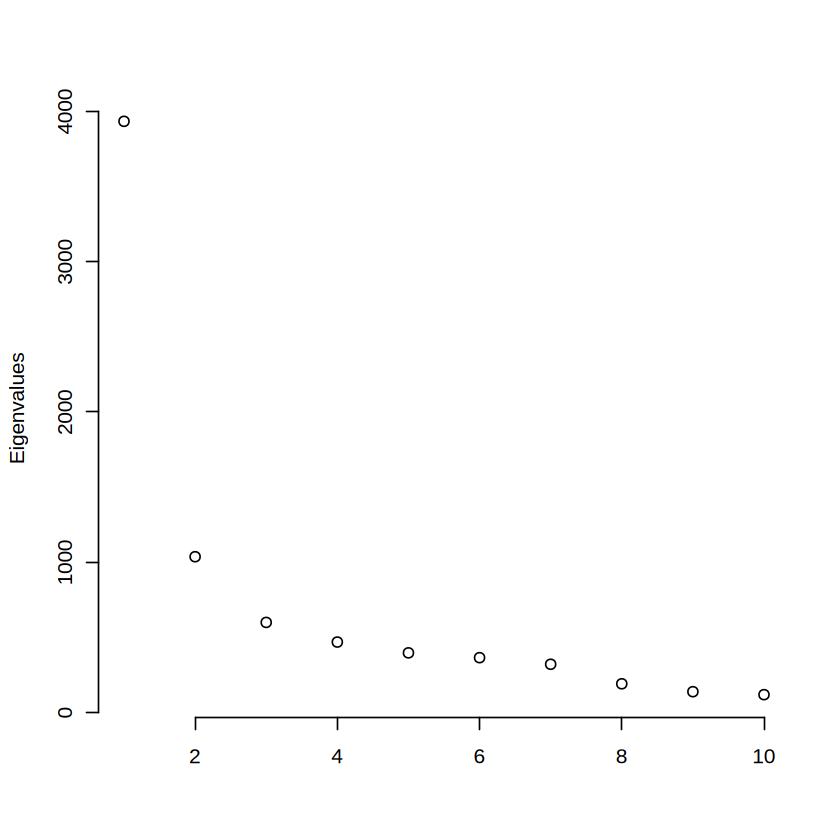

In [26]:
if (!exists("sce")) sce <- readRDS(file.path(MODELS_OUT, "sce.rds"))

# ~45 minutes
sce_rankGMF <- runRankGMF(
    sce[common_features, ],
    exprs_values = "precursors_log",
    family       = gaussian(),
    maxcomp      = 10,
    BPPARAM      = MulticoreParam(workers = 64)
)

fig <- plotRank(sce_rankGMF, maxcomp = 10)

save_dir <- file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder)
if (!is.null(save_dir)) {
    save_figure(fig, file.path(save_dir, "rank_gmf"), width = 8, height = 5)
}

### 5.2 Run GMF

Fits a 4-component GMF to each correction stage.
**Parameters used:**

| Parameter | Value | Meaning |
|---|---|---|
| `ncomponents` | `4` | Number of latent dimensions (from rank plot) |
| `family` | `gaussian()` | Gaussian noise model (appropriate for log-transformed data) |
| `exprs_values` | `"precursors_log"` | Use the log-transformed intensity matrix |

In [27]:
N_COMPONENTS <- 4

# Full SCE (no ntop — captures complete structure)
cat("[1/5] Running GMF on full SCE...\n")
sce_GMF <- runGMF(
    sce[common_features, ],
    exprs_values = "precursors_log",
    family       = gaussian(),
    ncomponents  = N_COMPONENTS,
    name         = "GMF",
    BPPARAM      = MulticoreParam(workers = 64)
)
saveRDS(sce_GMF, file.path(MODELS_OUT, subfolder, "sce_GMF.rds"))
cat("  Saved: sce_GMF.rds\n\n")

if (!exists("sce_norm"))  sce_norm  <- readRDS(file.path(MODELS_OUT, subfolder, "sce_norm.rds"))
if (!exists("sce_plate")) sce_plate <- readRDS(file.path(MODELS_OUT, subfolder, "sce_plate.rds"))
if (!exists("sce_batch")) sce_batch <- readRDS(file.path(MODELS_OUT, subfolder, "sce_batch.rds"))
if (!exists("sce_resid")) sce_resid <- readRDS(file.path(MODELS_OUT, subfolder, "sce_resid.rds"))

[1/5] Running GMF on full SCE...


  Saved: sce_GMF.rds



In [28]:
N_COMPONENTS <- 4

stages <- list(
    list(obj_name = "sce_norm",  features = vaRes_norm$Residuals$feature,  name = "sce_norm",  label = "[2/5] Post-normalisation"),
    list(obj_name = "sce_plate", features = vaRes_plate$Residuals$feature, name = "sce_plate", label = "[3/5] Post-plate"),
    list(obj_name = "sce_batch", features = vaRes_batch$Residuals$feature, name = "sce_batch", label = "[4/5] Post-batch"),
    list(obj_name = "sce_resid", features = vaRes_batch$Residuals$feature, name = "sce_resid", label = "[5/5] Residuals only")
)

for (stage in stages) {
    cat(sprintf("%s...\n", stage$label))

    obj             <- get(stage$obj_name)  # fetch by name, not copied upfront
    features_to_use <- intersect(common_features, stage$features)
    obj_filtered    <- obj[features_to_use, ]

    cat(sprintf("  Features going into GMF : %d\n", nrow(obj_filtered)))

    gmf <- runGMF(
        obj_filtered,
        exprs_values = "precursors_log",
        family       = gaussian(),
        ncomponents  = N_COMPONENTS,
        name         = "GMF",
        BPPARAM      = MulticoreParam(workers = 64)
    )

    out_name <- paste0(stage$name, "_GMF")
    assign(out_name, gmf)
    saveRDS(gmf, file.path(MODELS_OUT, subfolder, paste0(out_name, ".rds")))
    cat(sprintf("  Saved: %s.rds\n\n", out_name))
}

[2/5] Post-normalisation...
  Features going into GMF : 13132
  Saved: sce_norm_GMF.rds

[3/5] Post-plate...
  Features going into GMF : 13496
  Saved: sce_plate_GMF.rds

[4/5] Post-batch...
  Features going into GMF : 13549
  Saved: sce_batch_GMF.rds

[5/5] Residuals only...
  Features going into GMF : 13549
  Saved: sce_resid_GMF.rds



### 5.3 Plot Reduced Dimensions

Colours the first two GMF components by key metadata. The expected pattern after successive correction:

- **Full SCE** (`sce_GMF`): cells cluster by `plate_id` and `source.name` simultaneously — both batch and biology visible.
- **Post-normalisation** (`sce_norm_GMF`): intensity-scale batch reduced; `plate_id` clusters may persist.
- **Post-plate** (`sce_plate_GMF`): plate clustering dissolved; `comment.X.position.` may still separate.
- **Post-batch** (`sce_batch_GMF`): cells should separate primarily by `source.name` (biology), with `plate_id` clusters absent.

In [29]:
# For filter_samples

if (!exists("sce_GMF"))       sce_GMF       <- readRDS(file.path(MODELS_OUT, subfolder, "sce_GMF.rds"))
if (!exists("sce_norm_GMF"))  sce_norm_GMF  <- readRDS(file.path(MODELS_OUT, subfolder, "sce_norm_GMF.rds"))
if (!exists("sce_plate_GMF")) sce_plate_GMF <- readRDS(file.path(MODELS_OUT, subfolder, "sce_plate_GMF.rds"))
if (!exists("sce_batch_GMF")) sce_batch_GMF <- readRDS(file.path(MODELS_OUT, subfolder, "sce_batch_GMF.rds"))
if (!exists("sce_resid_GMF")) sce_resid_GMF <- readRDS(file.path(MODELS_OUT, subfolder, "sce_resid_GMF.rds"))

plot_gmf_embedding(
    sce_GMF,
    title    = "Full model",
    save_dir = file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder),
    filename = "gmf_full",
    show = FALSE
)
plot_gmf_embedding(
    sce_norm_GMF,
    title    = "Post-normalisation",
    save_dir = file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder),
    filename = "gmf_norm",
    show = FALSE
)
plot_gmf_embedding(
    sce_plate_GMF,
    title    = "Post-plate correction",
    save_dir = file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder),
    filename = "gmf_plate",
    show = FALSE
)
plot_gmf_embedding(
    sce_batch_GMF,
    title    = "Post-batch correction",
    save_dir = file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder),
    filename = "gmf_batch",
    show = FALSE
)
plot_gmf_embedding(
    sce_resid_GMF,
    title    = "Residuals only",
    save_dir = file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder),
    filename = "gmf_resid",
    show = FALSE
)

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is

--- Full model ---


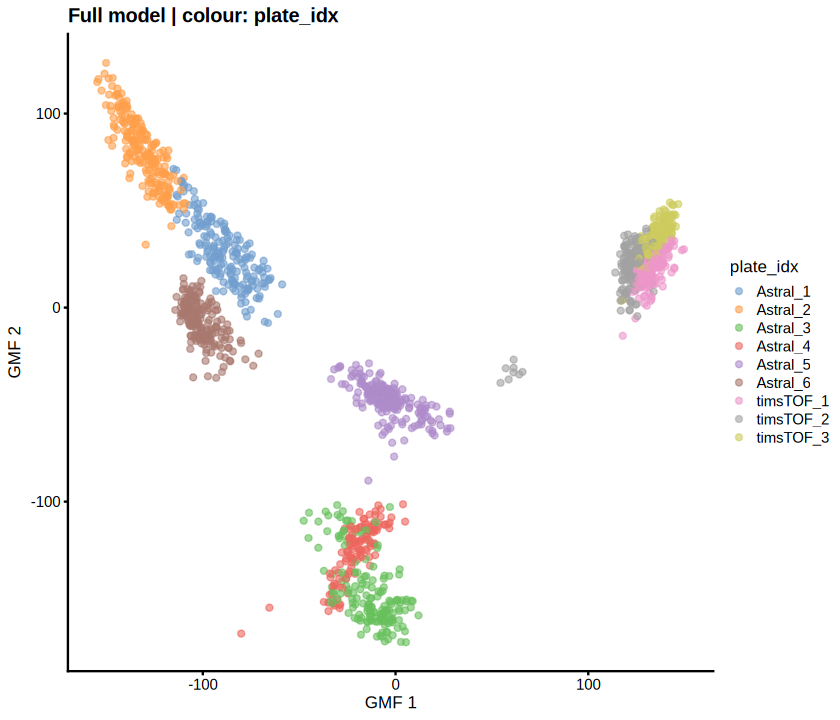

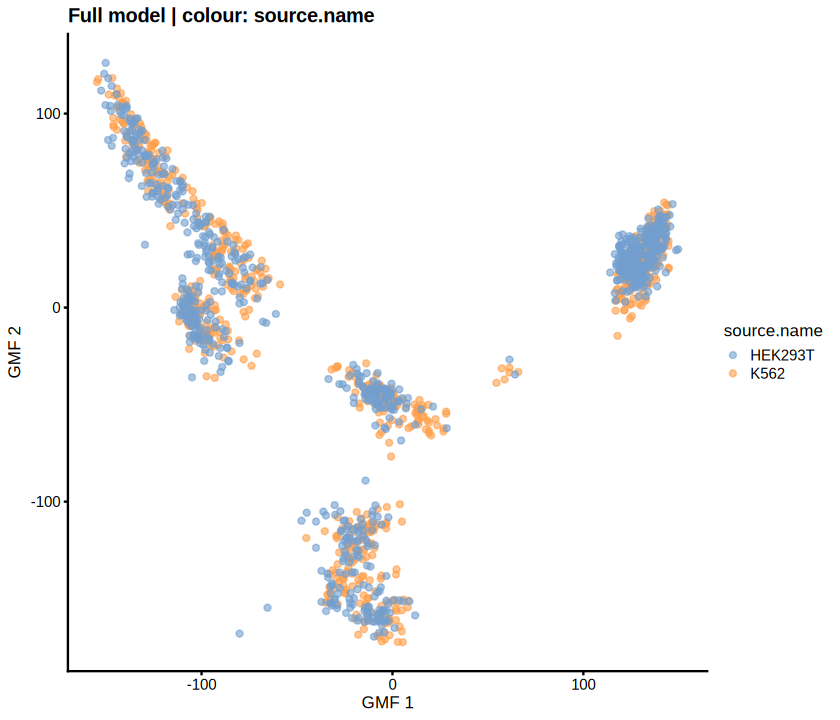

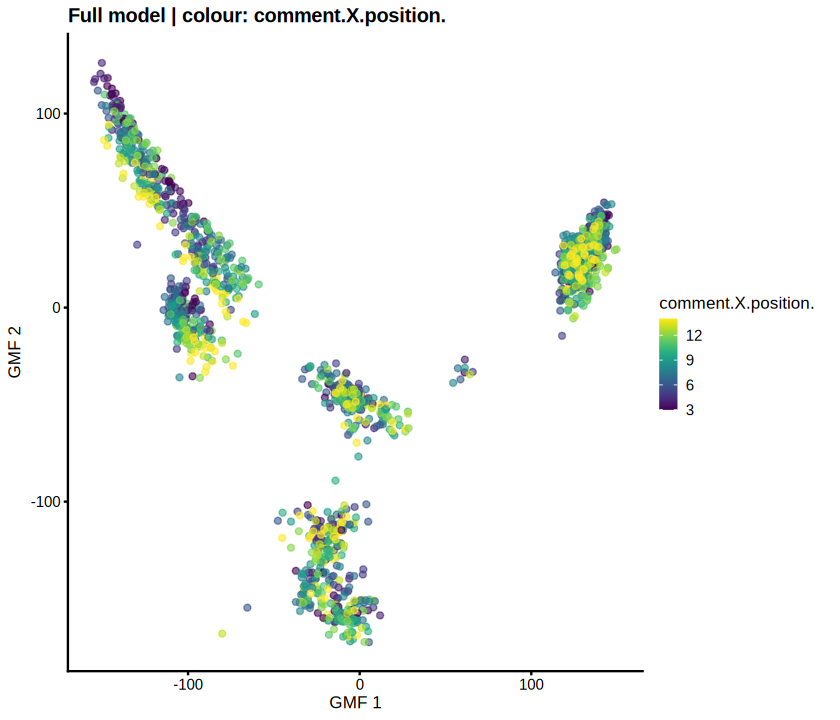

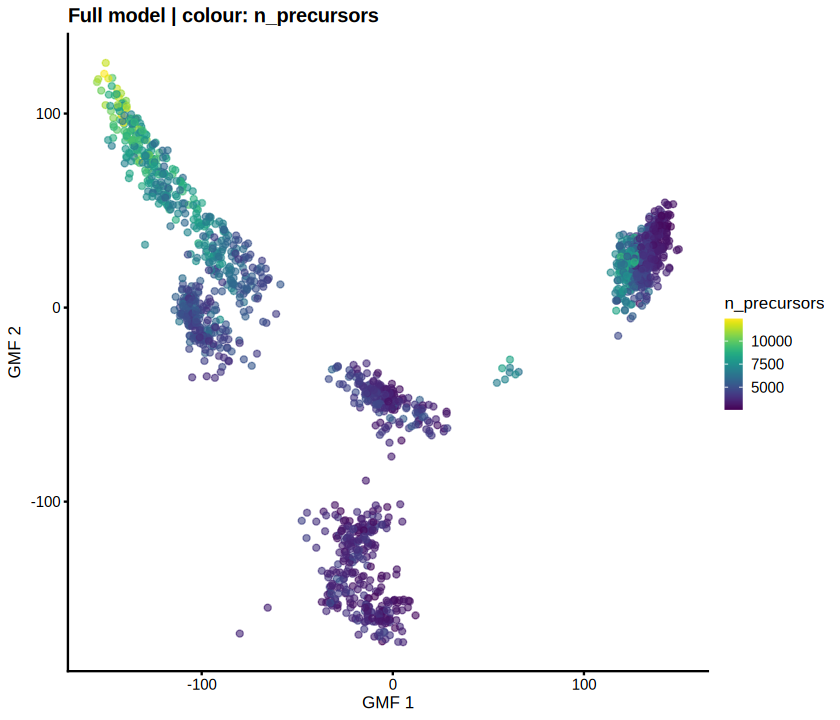

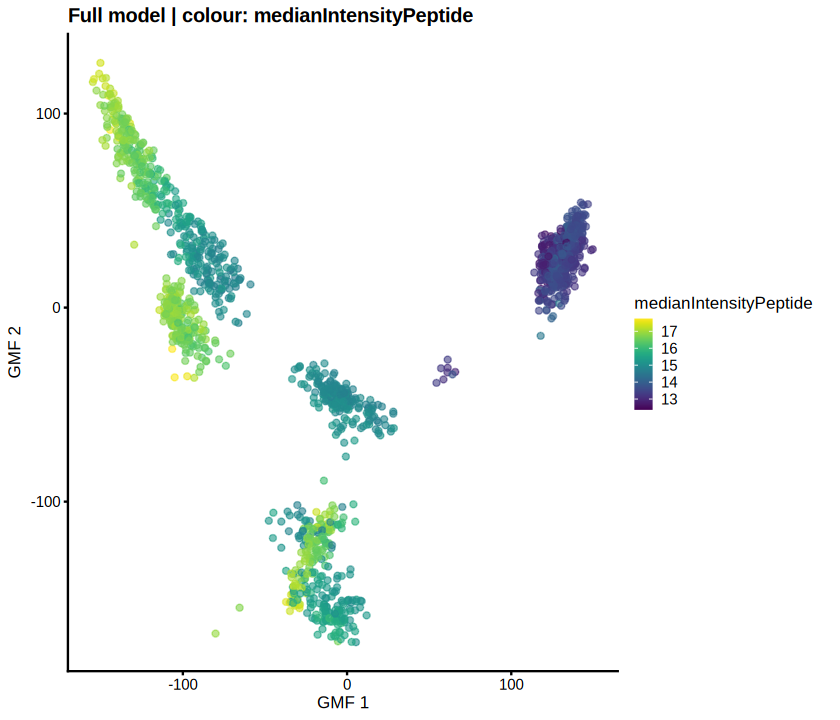

--- Post-normalisation ---


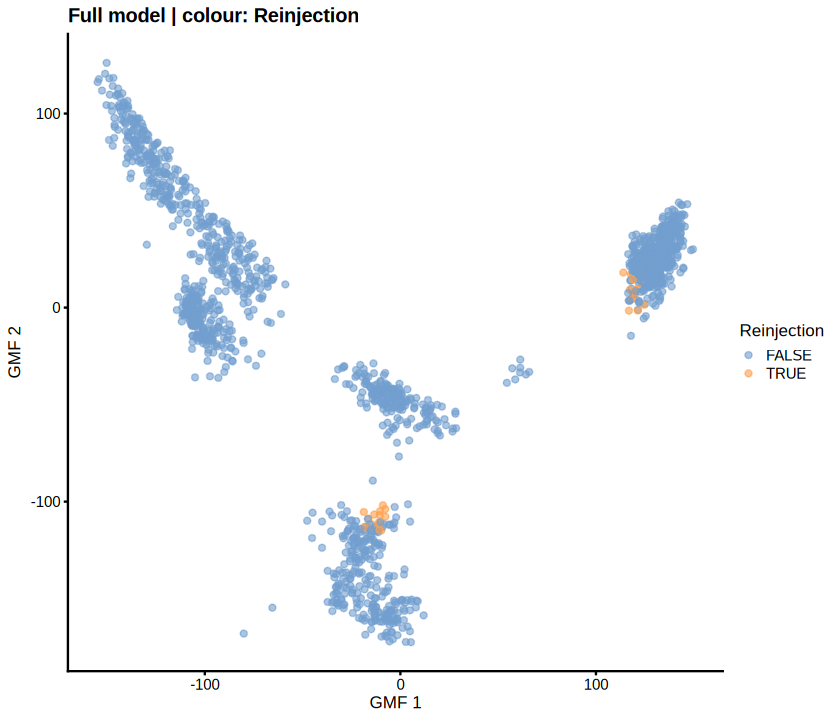

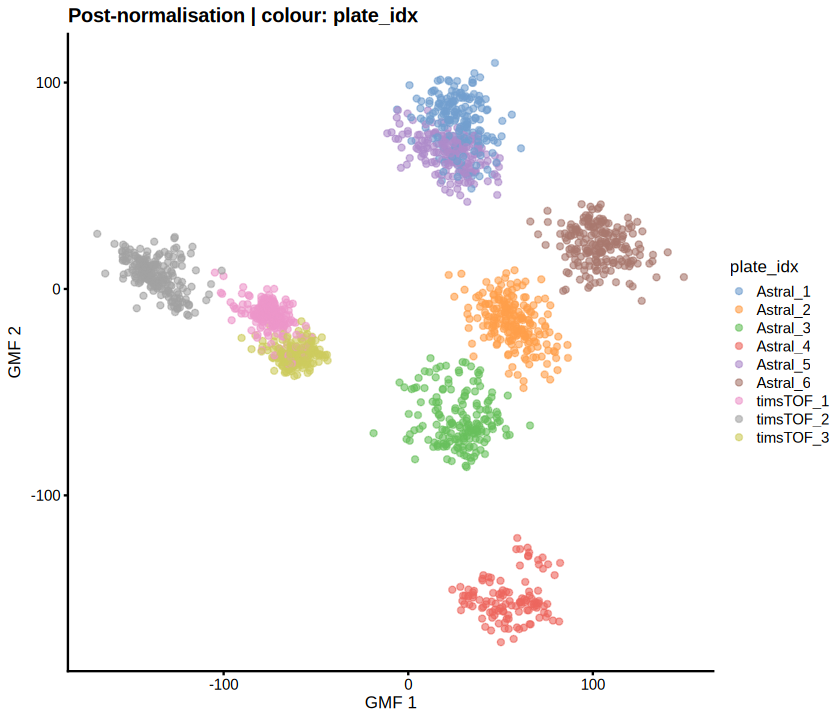

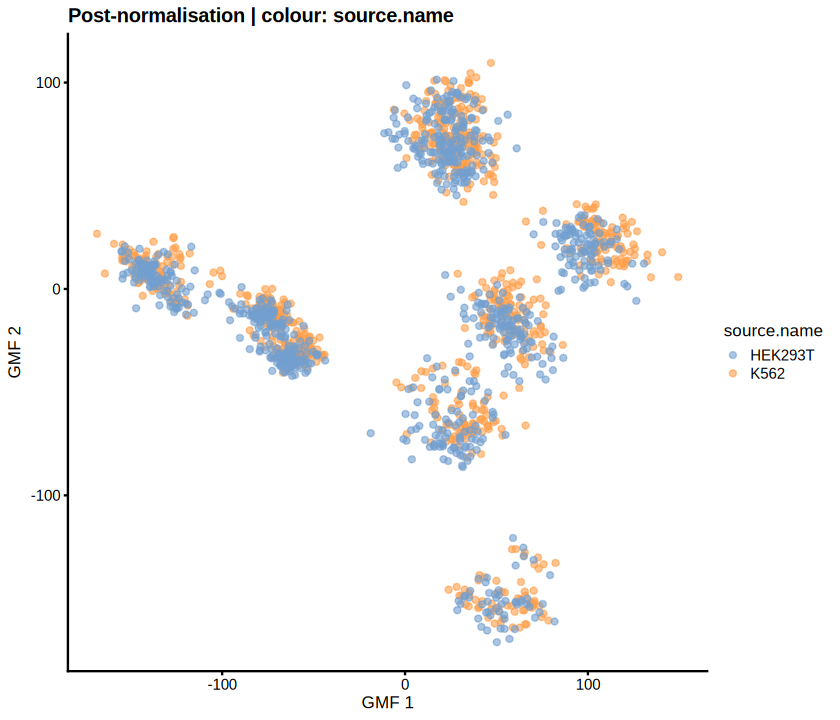

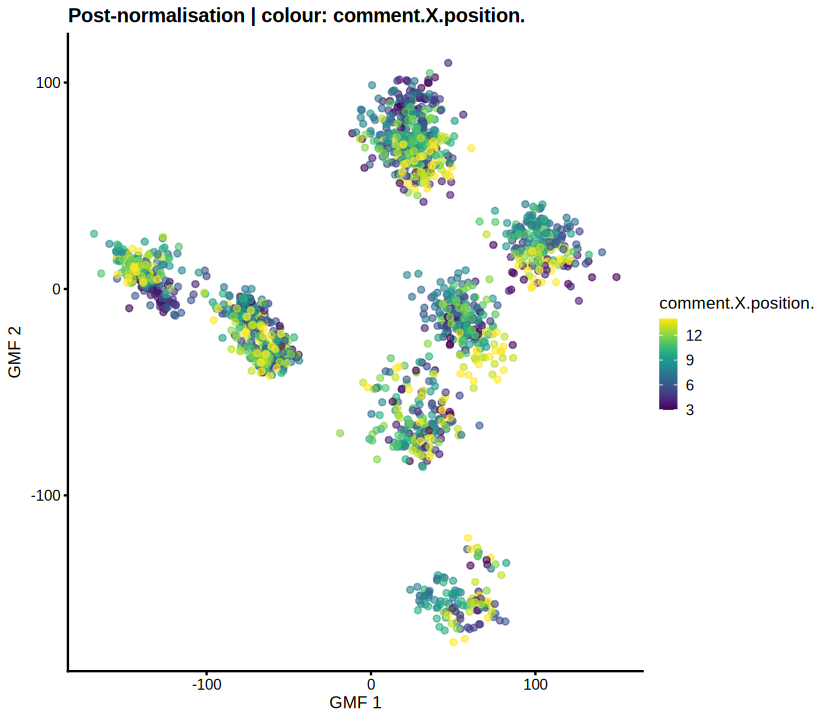

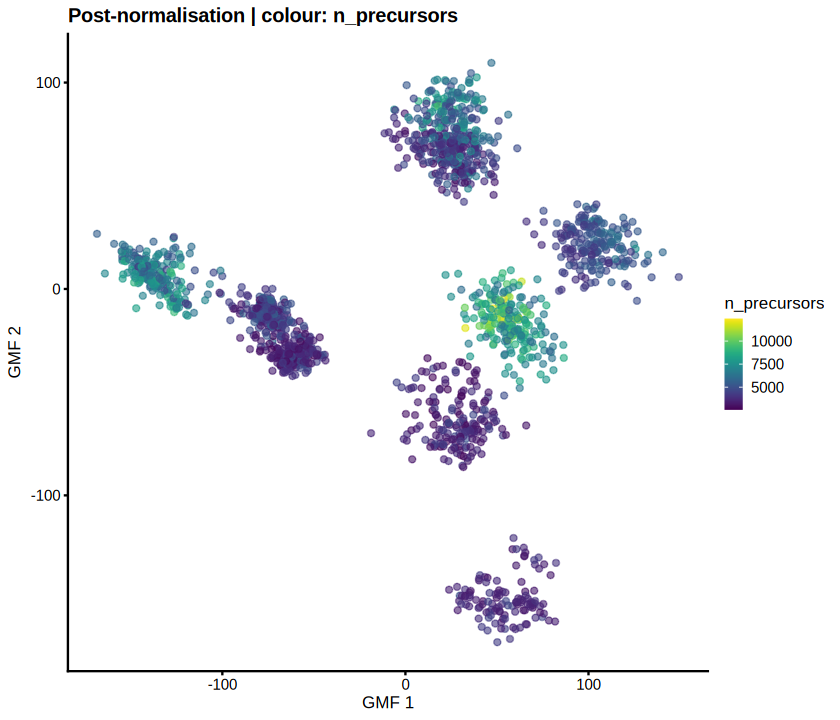

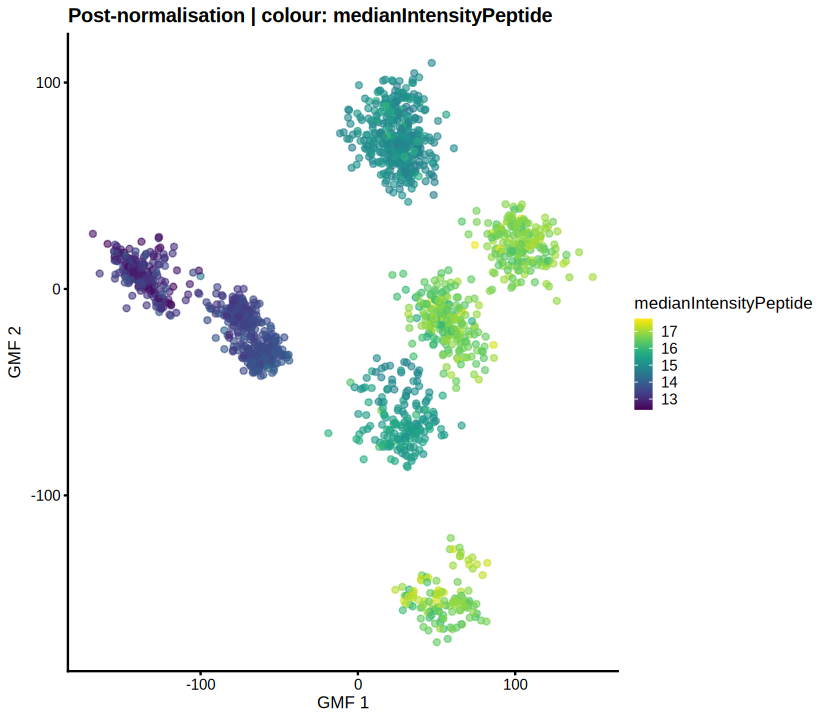

--- Post-plate correction ---


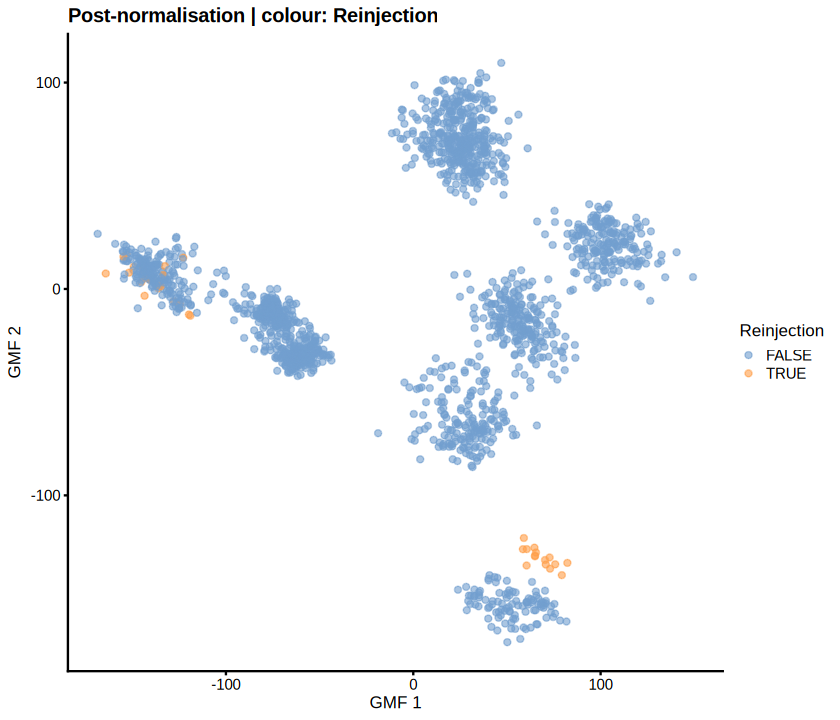

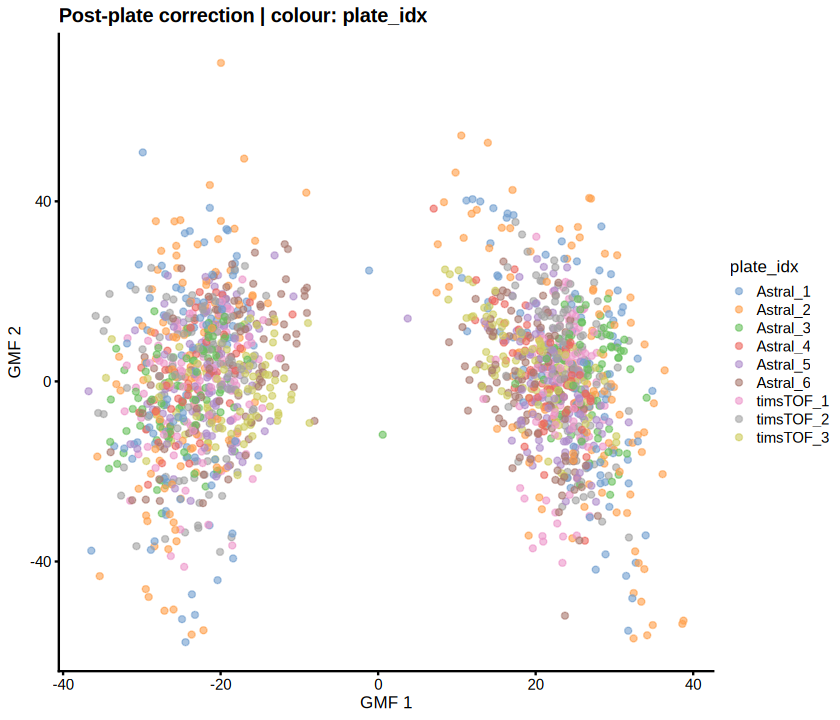

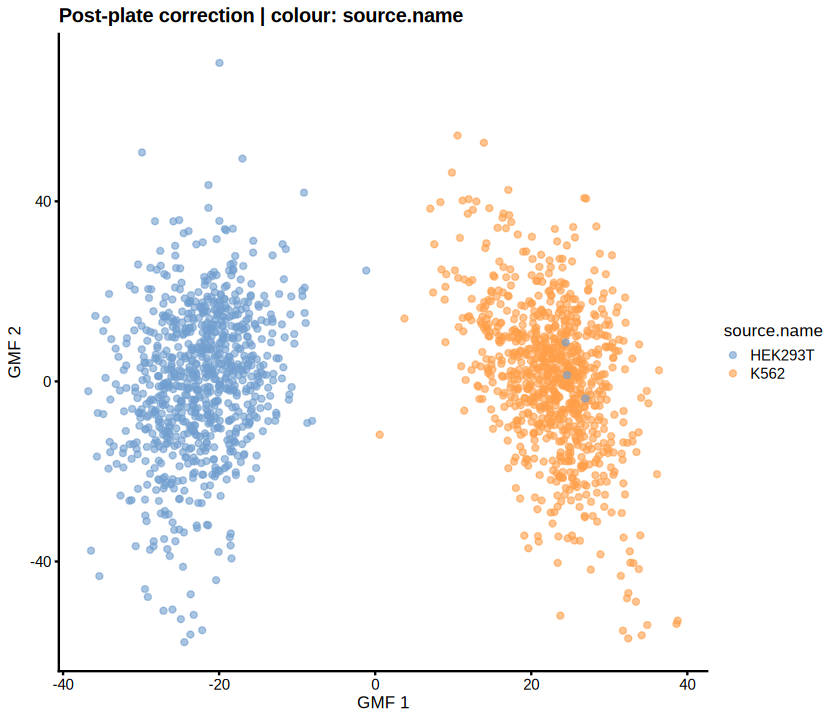

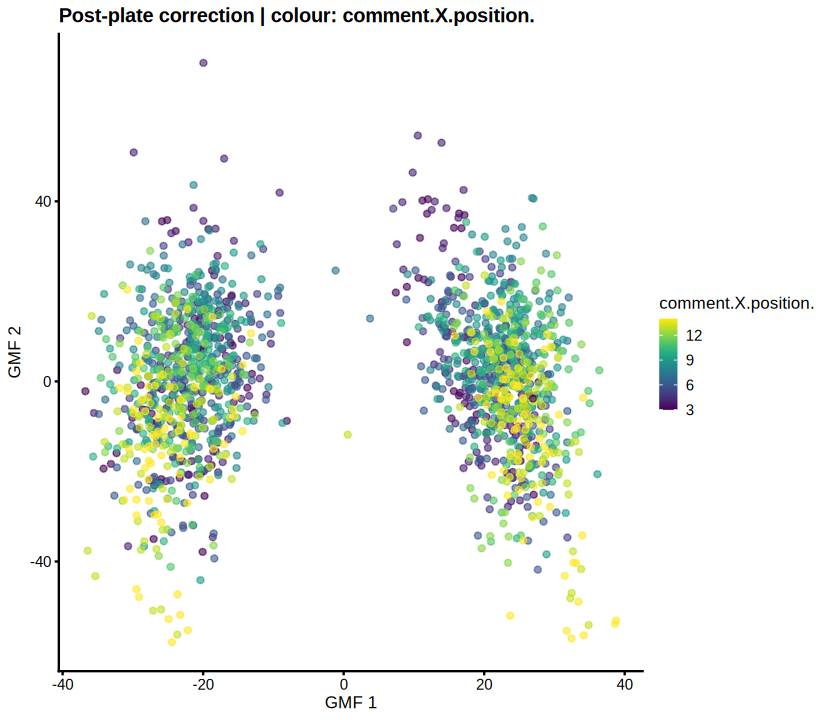

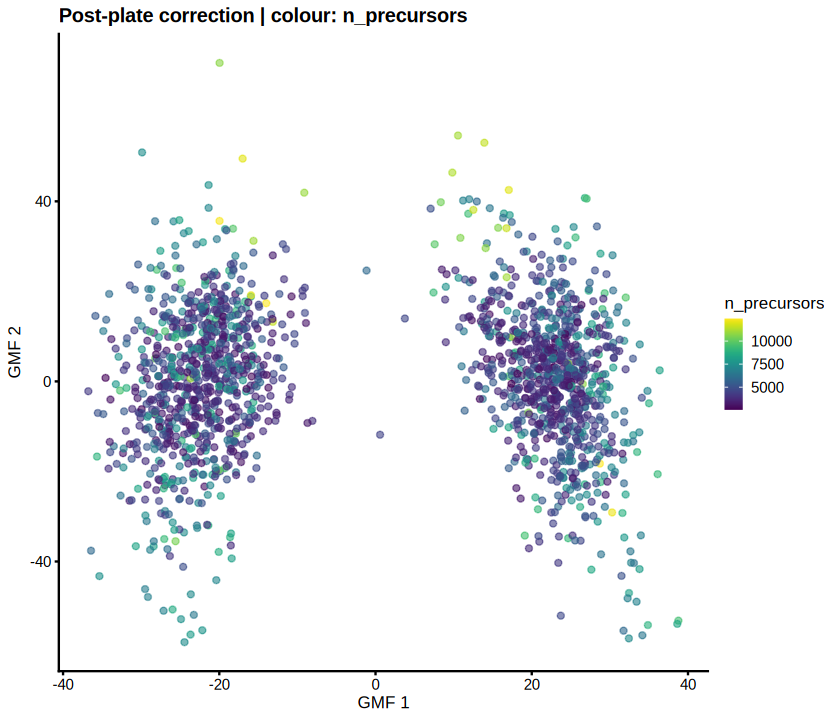

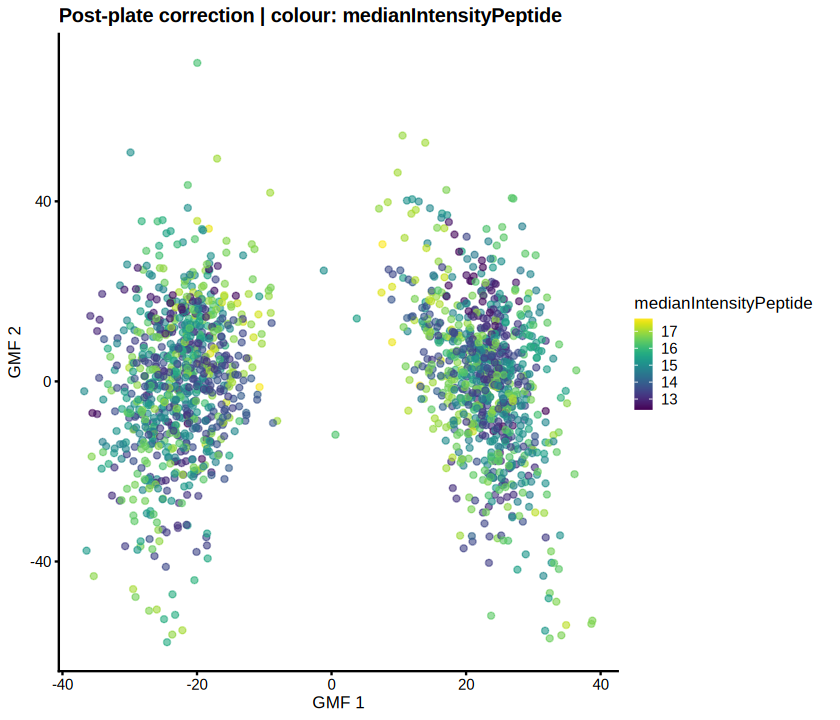

--- Post-batch correction ---


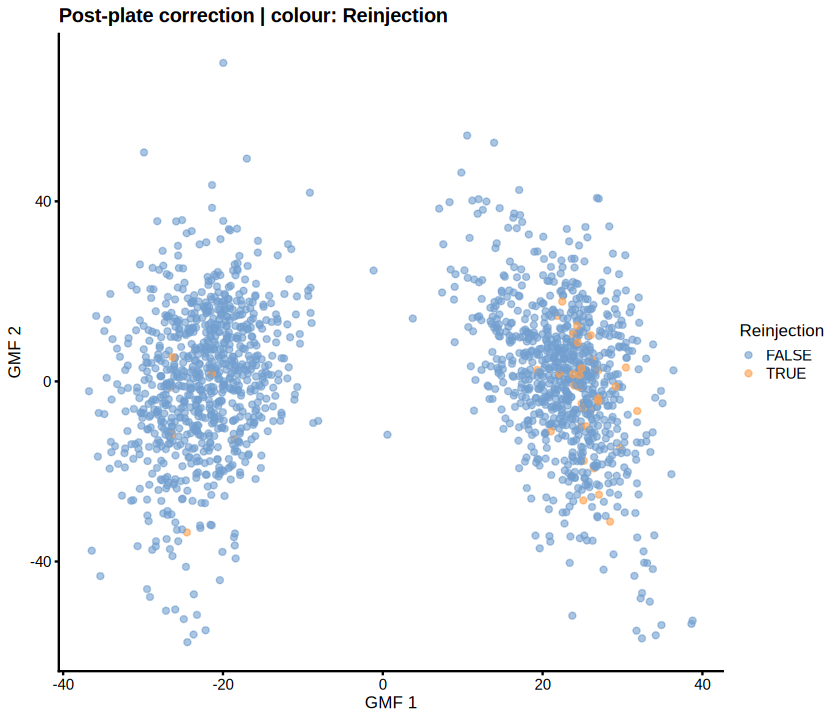

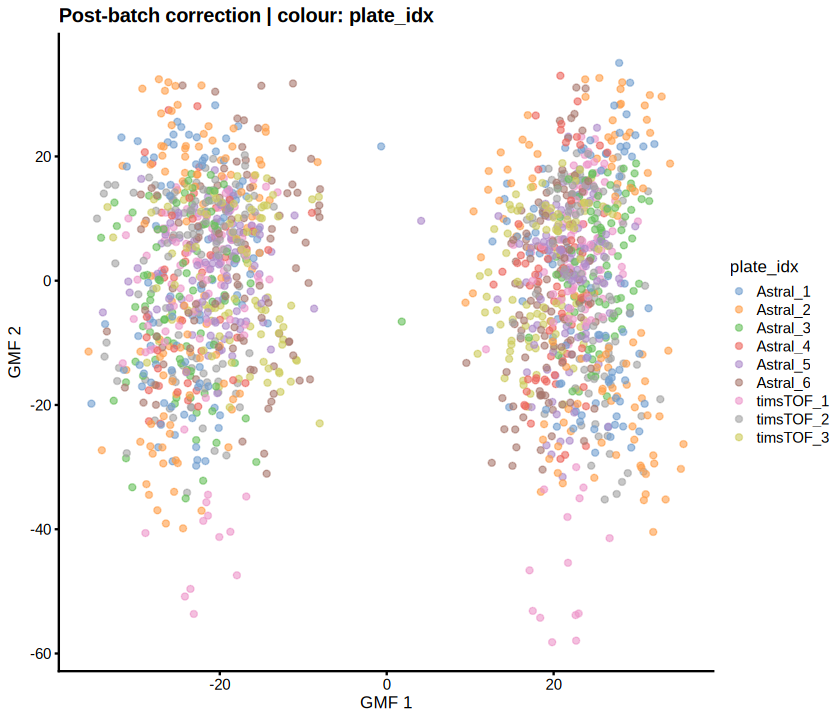

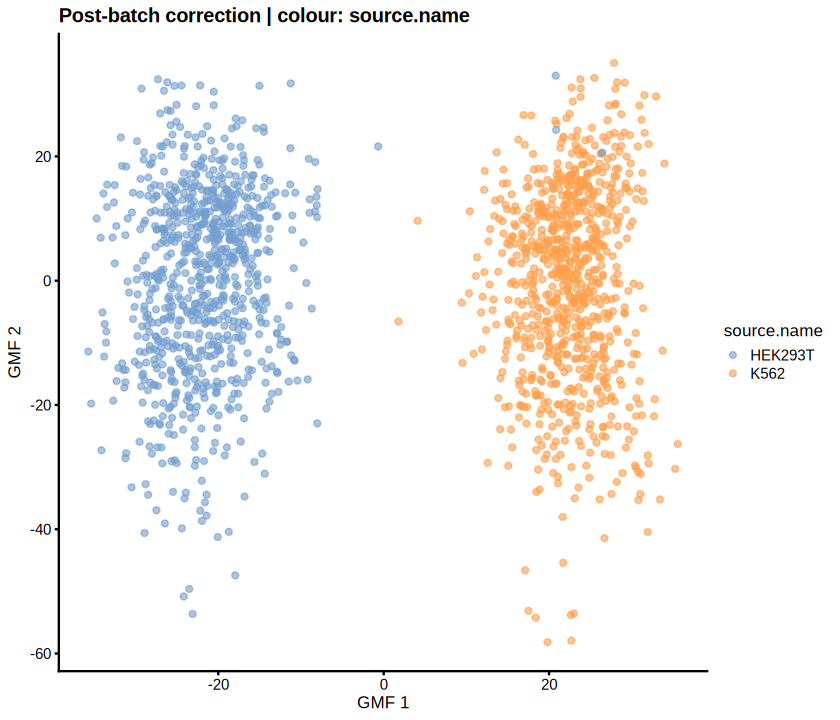

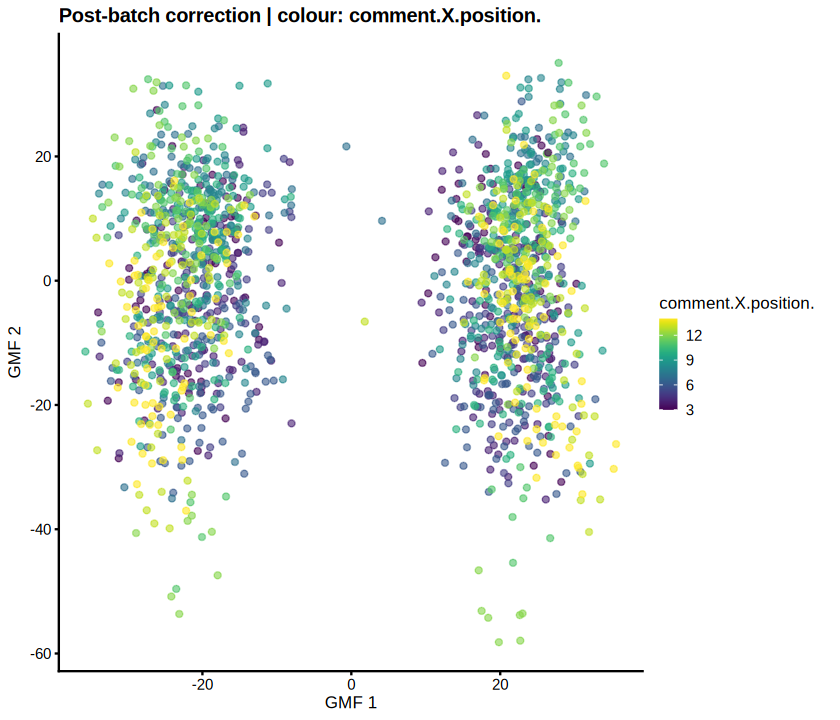

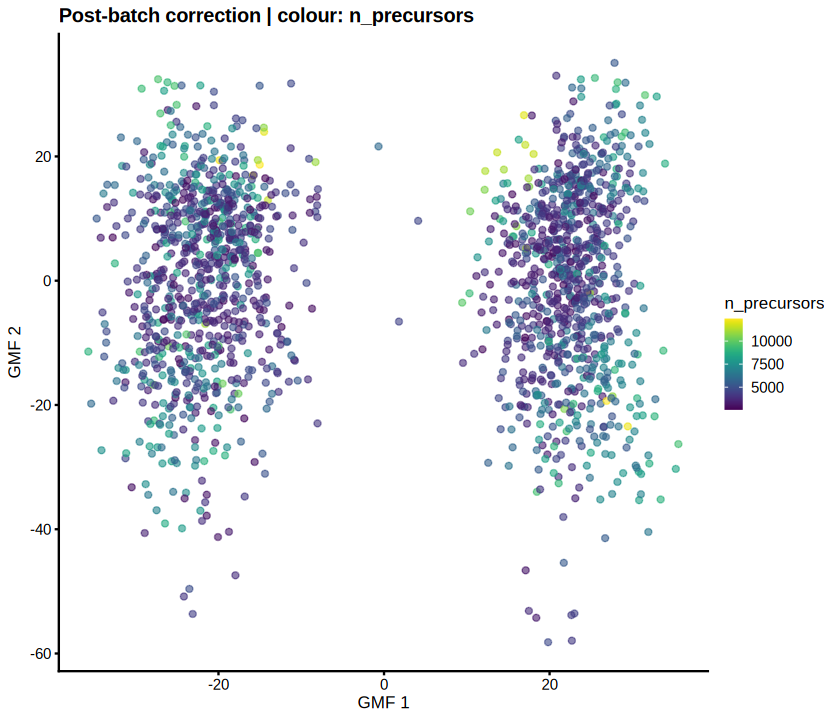

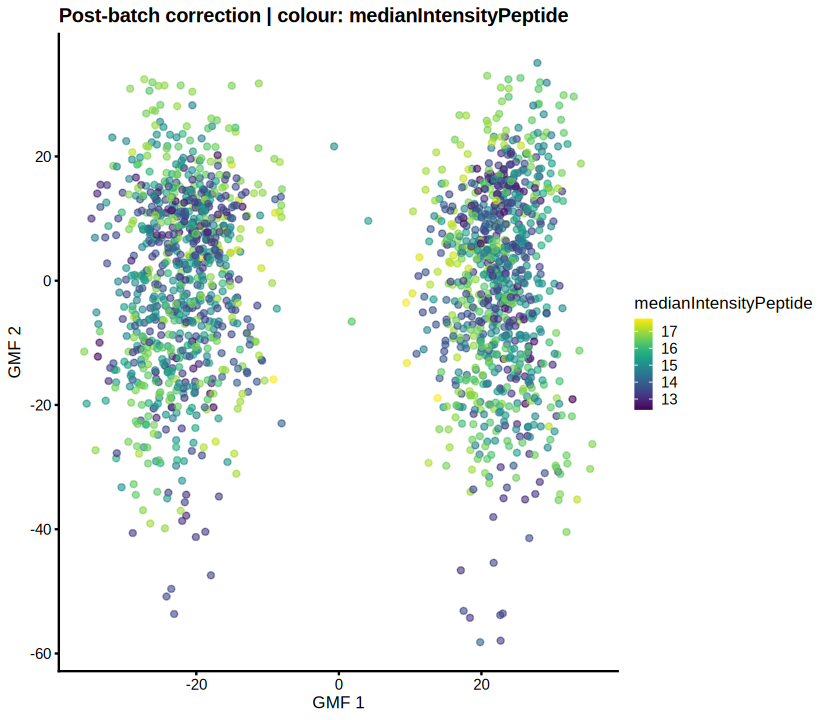

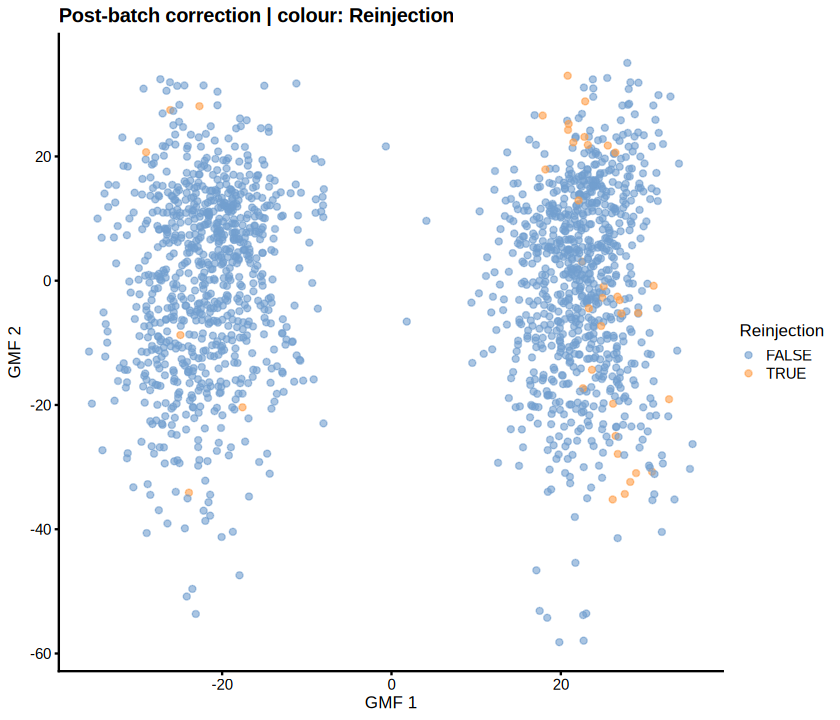

In [30]:
if (!exists("sce_GMF"))       sce_GMF       <- readRDS(file.path(MODELS_OUT, "sce_GMF.rds"))
if (!exists("sce_norm_GMF"))  sce_norm_GMF  <- readRDS(file.path(MODELS_OUT, "sce_norm_GMF.rds"))
if (!exists("sce_plate_GMF")) sce_plate_GMF <- readRDS(file.path(MODELS_OUT, "sce_plate_GMF.rds"))
if (!exists("sce_batch_GMF")) sce_batch_GMF <- readRDS(file.path(MODELS_OUT, "sce_batch_GMF.rds"))

colour_dims <- c("plate_idx", "source.name", "comment.X.position.",
                 "n_precursors", "medianIntensityPeptide", "Reinjection")

options(repr.plot.width = 7, repr.plot.height = 6)

for (stage in list(
    list(obj = sce_GMF,       label = "Full model"),
    list(obj = sce_norm_GMF,  label = "Post-normalisation"),
    list(obj = sce_plate_GMF, label = "Post-plate correction"),
    list(obj = sce_batch_GMF, label = "Post-batch correction")
)) {
    cat(sprintf("--- %s ---\n", stage$label))
    for (col_by in colour_dims) {
        tryCatch(
            print(
                plotReducedDim(stage$obj, dimred = "GMF", colour_by = col_by) +
                    ggtitle(sprintf("%s | colour: %s", stage$label, col_by))
            ),
            error = function(e) message(sprintf("  Skipping %s: %s", col_by, e$message))
        )
    }
}

### 5.4 Batch Mixing and Biological Separation

Quantifies the quality of each correction stage numerically using average silhouette widths computed on the first four GMF components. Two complementary scores are reported per stage:

| Metric | Variable scored | Interpretation |
|---|---|---|
| **Biological separation** | `source.name` | Higher → cell types form more distinct clusters in embedding space |
| **Batch structure** | `plate_idx` | Lower (towards −1) → cells are well-mixed across plates; no plate clustering |

A successful batch correction should show **increasing** biological silhouette and **decreasing** batch silhouette as correction progresses. If both decrease together, the correction is over-fitting and eroding biological structure alongside batch effects.

> Silhouette scores are computed on the first four GMF dimensions for speed; using more components may give slightly different absolute values but the relative ordering across stages should be stable.

In [31]:
library(cluster)

compute_silhouettes <- function(gmf_obj, n_dims = 4,
                                batch_var = "plate_id",
                                bio_var   = "source.name") {
    coords    <- reducedDim(gmf_obj, "GMF")[, seq_len(n_dims)]
    cd        <- colData(gmf_obj)
    d_mat     <- dist(coords)
    bio_sil   <- mean(silhouette(as.integer(factor(cd[[bio_var]])),   d_mat)[, 3])
    batch_sil <- mean(silhouette(as.integer(factor(cd[[batch_var]])), d_mat)[, 3])
    data.frame(bio_silhouette = bio_sil, batch_silhouette = batch_sil)
}

  Computing silhouettes: Full model...
  Computing silhouettes: Post-normalisation...
  Computing silhouettes: Post-plate...
  Computing silhouettes: Post-batch...

Silhouette scores per correction stage:
               stage bio_silhouette batch_silhouette
1         Full model   0.0004218116       0.64359216
2 Post-normalisation   0.0026478347       0.69658701
3         Post-plate   0.4109105277      -0.04558363
4         Post-batch   0.4389309642      -0.05124201


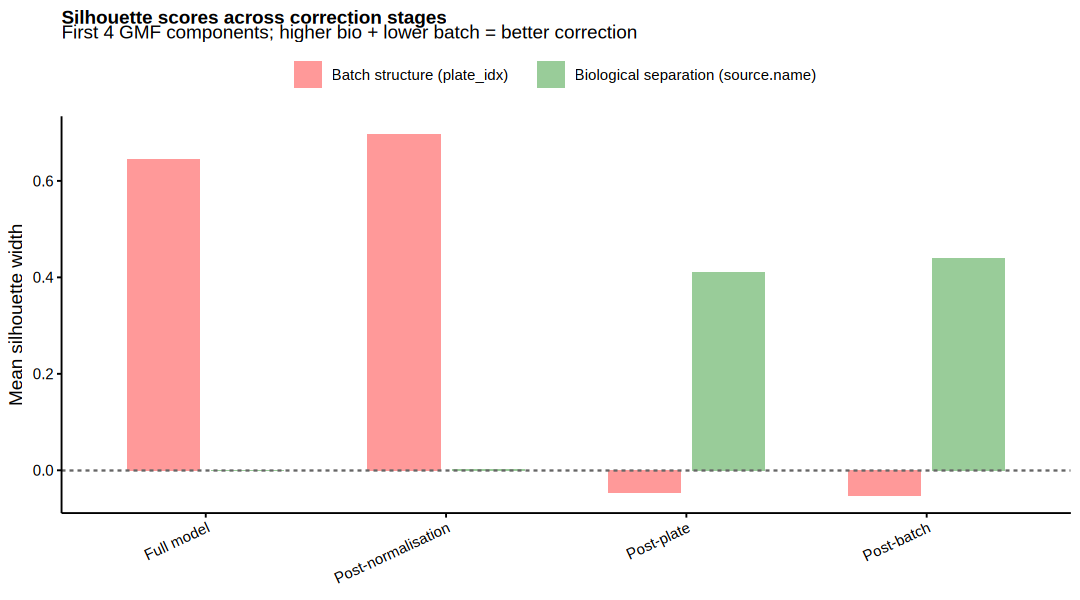

In [32]:
stage_list <- list(
    "Full model"         = sce_GMF,
    "Post-normalisation" = sce_norm_GMF,
    "Post-plate"         = sce_plate_GMF,
    "Post-batch"         = sce_batch_GMF
)

plot_silhouette_scores(
    stage_list = stage_list,
    save_dir   = file.path(FIGURES_OUT, "Figure_6", "scplainer", subfolder),
    show       = TRUE
)

## 6. Differential Expression Analysis

Tests for differential abundance between K562 and HEK293T cells at each correction stage using `scpDifferentialAnalysis`, which applies a moderated t-test per precursor via the fitted scplainer model. Results are visualised as volcano plots.

**Interpreting the correction-stage comparison:**
- More significant hits after batch correction indicate that batch noise was suppressing differential signal.
- Similar hit lists across stages support that the biological contrast is robust to technical variation.
- Hits appearing only after batch correction should be treated cautiously — they may be regression artefacts.

$source.name_HEK293T_vs_K562


  Saved: de_results.rds


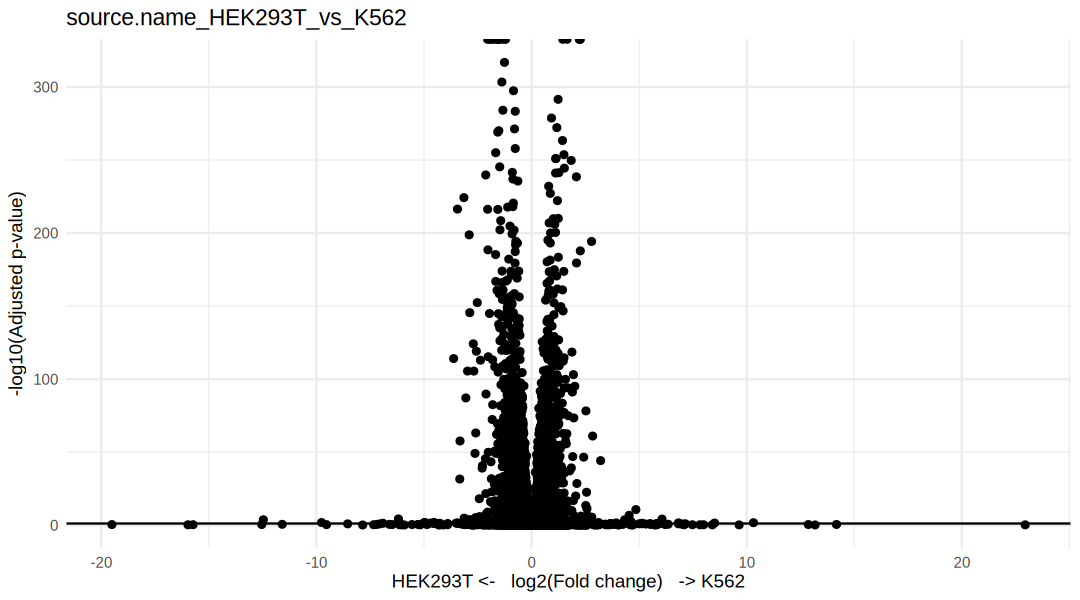

In [36]:
contrast <- list(c("source.name", "HEK293T", "K562"))
res <- scpDifferentialAnalysis(
    sce,
    contrasts = contrast
)
de_results <- res$source.name_HEK293T_vs_K562
p   <- scpVolcanoPlot(res)
p

saveRDS(de_results, file.path(MODELS_OUT, subfolder, "de_results.rds"))
cat("  Saved: de_results.rds\n")

## 7. Export

Converts the batch-corrected SCE (`sce_batch`) to AnnData format for downstream Python-based analyses. The model metadata is stripped before conversion to avoid serialisation issues. The exported file is written to `MODELS_OUT/sce_batch.h5ad` and can be read directly with `anndata.read_h5ad()` in Python.

In [37]:
subfolder <- 'base'  # or 'filter_samples' for the version with Diameter covariate included

# Load SCE objects if not already in the environment
sce <- readRDS(file.path(MODELS_OUT, subfolder, "sce.rds"))
sce_norm  <- readRDS(file.path(MODELS_OUT, subfolder, "sce_norm.rds"))
sce_plate <- readRDS(file.path(MODELS_OUT, subfolder, "sce_plate.rds"))
sce_batch <- readRDS(file.path(MODELS_OUT, subfolder, "sce_batch.rds"))
sce_resid <- readRDS(file.path(MODELS_OUT, subfolder, "sce_resid.rds"))

rename_assay <- function(obj, new_name = "precursors_log") {
    if (length(assays(obj)) == 0) {
        stop("Object has no assays")
    }
    assayNames(obj)[1] <- new_name
    obj
}

sce       <- rename_assay(sce)
sce_norm  <- rename_assay(sce_norm)
sce_plate <- rename_assay(sce_plate)
sce_batch <- rename_assay(sce_batch)
sce_resid <- rename_assay(sce_resid)

# verify
lapply(
    list(
        sce = sce, 
        sce_norm = sce_norm,
        sce_plate = sce_plate,
        sce_batch = sce_batch,
        sce_resid = sce_resid
    ),
    assayNames
)

# Load DE results if not already in the environment
if (!exists("de_results")) de_results <- readRDS(file.path(MODELS_OUT, subfolder, "de_results.rds"))

# Load vaRes objects if not already in the environment-
if (!exists("vaRes_full"))  vaRes_full  <- readRDS(file.path(MODELS_OUT, subfolder, "vaRes_full.rds"))
if (!exists("vaRes_norm"))  vaRes_norm  <- readRDS(file.path(MODELS_OUT, subfolder, "vaRes_norm.rds"))
if (!exists("vaRes_plate")) vaRes_plate <- readRDS(file.path(MODELS_OUT, subfolder, "vaRes_plate.rds"))
if (!exists("vaRes_batch")) vaRes_batch <- readRDS(file.path(MODELS_OUT, subfolder, "vaRes_batch.rds"))

# Load the GMF models if not already in the environment
if (!exists("sce_GMF"))       sce_GMF       <- readRDS(file.path(MODELS_OUT, subfolder, "sce_GMF.rds"))
if (!exists("sce_norm_GMF"))  sce_norm_GMF  <- readRDS(file.path(MODELS_OUT, subfolder, "sce_norm_GMF.rds"))
if (!exists("sce_plate_GMF")) sce_plate_GMF <- readRDS(file.path(MODELS_OUT, subfolder, "sce_plate_GMF.rds"))
if (!exists("sce_batch_GMF")) sce_batch_GMF <- readRDS(file.path(MODELS_OUT, subfolder, "sce_batch_GMF.rds"))
if (!exists("sce_resid_GMF")) sce_resid_GMF <- readRDS(file.path(MODELS_OUT, subfolder, "sce_resid_GMF.rds"))

$sce
[1] "precursors_log"

$sce_norm
[1] "precursors_log"

$sce_plate
[1] "precursors_log"

$sce_batch
[1] "precursors_log"

$sce_resid
[1] "precursors_log"

In [38]:
# ── export_to_anndata.R ───────────────────────────────────────────────────────
# Combines all scplainer outputs into a single SCE and exports to .h5ad
# ─────────────────────────────────────────────────────────────────────────────
library(SingleCellExperiment)
library(zellkonverter)
library(S4Vectors)

# ── 0. Parameters ─────────────────────────────────────────────────────────────
H5AD_OUT <- file.path(MODELS_OUT, subfolder, "scplainer_results.h5ad")

# ── 1. Define common feature space ────────────────────────────────────────────
# Use common_features (computed earlier) as the canonical feature index
# This is the intersection of features passing n/p filter in the full model
# and features present in all corrected SCE objects
cat("Building common feature space...\n")
cat(sprintf("  Common features: %d\n", length(common_features)))

# ── 2. Build base SCE with all intensity layers ───────────────────────────────
cat("Building base SCE with intensity layers...\n")

# use sce as base, subset to common features
sce_base <- sce[common_features, ]
# clear metadata — scpModel objects are not serializable to h5ad
# model formulas are preserved separately in metadata(sce_base)$scplainer_model_formulas
metadata(sce_base) <- list()

# add corrected assays — subset each to common features and reorder columns
# to match base SCE column order
cell_order <- colnames(sce_base)

add_assay <- function(sce_obj, assay_name_in, assay_name_out) {
    mat <- assay(sce_obj[common_features, cell_order], assay_name_in)
    assay(sce_base, assay_name_out) <<- mat
}

names(assays(sce_base))[1] <- "log2_raw"  # rename primary assay to match input SCEs
add_assay(sce_norm,  "precursors_log", "log2_norm")
add_assay(sce_plate, "precursors_log", "log2_plate")
add_assay(sce_batch, "precursors_log", "log2_batch")
add_assay(sce_resid, "precursors_log", "log2_resid")

# rename primary assay
names(assays(sce_base))[1] <- "log2_raw"

cat(sprintf("  Assays: %s\n", paste(assayNames(sce_base), collapse = ", ")))

# ── 3. Add variance fractions to rowData (as separate DataFrames per covariate)
cat("Adding variance fractions to rowData...\n")

# helper: align a vaRes component to common_features, filling missing with NA
align_to_features <- function(df, features) {
    df_aligned <- data.frame(
        feature             = features,
        SS                  = NA_real_,
        df                  = NA_real_,
        percentExplainedVar = NA_real_
    )
    idx <- match(df$feature, features)
    valid <- !is.na(idx)
    df_aligned[idx[valid], "SS"]                  <- df$SS[valid]
    df_aligned[idx[valid], "df"]                  <- df$df[valid]
    df_aligned[idx[valid], "percentExplainedVar"] <- df$percentExplainedVar[valid]
    rownames(df_aligned) <- features
    df_aligned[, c("SS", "df", "percentExplainedVar")]
}

# build a named list of DataFrames per covariate for varm
# zellkonverter will store each element of metadata as a separate varm entry
varm_list <- list()
for (covariate in names(vaRes_full)) {
    key              <- paste0("vaRes_full_", covariate)
    varm_list[[key]] <- as.matrix(
        align_to_features(as.data.frame(vaRes_full[[covariate]]), common_features)
    )
    cat(sprintf("  Added varm: %s\n", key))
}

# store in reducedDims as a workaround — zellkonverter maps reducedDims to obsm
# and rowData to var, but varm needs to go via metadata then be handled in Python
# Instead we store as a special metadata list and handle in Python post-export
metadata(sce_base)$varm <- varm_list

# ── 3b. Add differential expression results to varm ───────────────────────────
cat("Adding differential expression results to varm...\n")

# align DE results to common_features, filling missing with NA
de_aligned <- data.frame(
    Estimate   = rep(NA_real_, length(common_features)),
    SE         = rep(NA_real_, length(common_features)),
    Df         = rep(NA_real_, length(common_features)),
    tstatistic = rep(NA_real_, length(common_features)),
    pvalue     = rep(NA_real_, length(common_features)),
    padj       = rep(NA_real_, length(common_features))
)
rownames(de_aligned) <- common_features

idx   <- match(de_results$feature, common_features)
valid <- !is.na(idx)

de_aligned[idx[valid], "Estimate"]   <- de_results$Estimate[valid]
de_aligned[idx[valid], "SE"]         <- de_results$SE[valid]
de_aligned[idx[valid], "Df"]         <- de_results$Df[valid]
de_aligned[idx[valid], "tstatistic"] <- de_results$tstatistic[valid]
de_aligned[idx[valid], "pvalue"]     <- de_results$pvalue[valid]
de_aligned[idx[valid], "padj"]       <- de_results$padj[valid]

cat(sprintf("  DE features aligned: %d / %d\n", sum(valid), nrow(de_results)))

# store in metadata$varm alongside vaRes entries
metadata(sce_base)$varm[["DE_scplainer_HEK293T_vs_K562"]] <- as.matrix(de_aligned)

# ── 4. Add GMF embeddings to reducedDims ──────────────────────────────────────
cat("Adding GMF embeddings to reducedDims...\n")

add_gmf <- function(sce_gmf_obj, key) {
    emb        <- reducedDim(sce_gmf_obj, "GMF")
    # reindex to match base SCE cell order
    emb_aligned           <- matrix(NA_real_,
                                    nrow     = ncol(sce_base),
                                    ncol     = ncol(emb),
                                    dimnames = list(cell_order, colnames(emb)))
    shared                <- intersect(rownames(emb), cell_order)
    emb_aligned[shared, ] <- emb[shared, ]
    reducedDim(sce_base, key) <<- emb_aligned
    cat(sprintf("  Added reducedDim: %s (%d cells, %d components)\n",
                key, nrow(emb_aligned), ncol(emb_aligned)))
}

add_gmf(sce_GMF,       "X_GMF_full")
add_gmf(sce_norm_GMF,  "X_GMF_norm")
add_gmf(sce_plate_GMF, "X_GMF_plate")
add_gmf(sce_batch_GMF, "X_GMF_batch")

# ── 5. Store model formulas and provenance in metadata ────────────────────────
cat("Storing model metadata...\n")

formula_to_string <- function(f) paste(deparse(f), collapse = " ")

metadata(sce_base)$scplainer_model_formulas <- list(
    full  = formula_to_string(metadata(sce)$model@scpModelFormula),
    norm  = formula_to_string(metadata(sce_norm)$model@scpModelFormula),
    plate = formula_to_string(metadata(sce_plate)$model@scpModelFormula),
    batch = formula_to_string(metadata(sce_batch)$model@scpModelFormula),
    resid = "no model fitted (pure residuals)"
)

metadata(sce_base)$scplainer_description <- list(
    source_h5ad    = "adata_precursor.h5ad",
    common_features = paste0(length(common_features), " features passing n/p > 20 in full model, ",
                             "present in all corrected SCE objects"),
    layers = list(
        log2_raw   = "log2 intensities, no correction",
        log2_norm  = "regressed out: medianIntensityPeptide, n_precursors",
        log2_plate = "regressed out: medianIntensityPeptide, n_precursors, plate_idx",
        log2_batch = "regressed out: medianIntensityPeptide, n_precursors, plate_idx, comment.X.position., injection_order",
        log2_resid = "regressed out: all batch effects + source.name"
    ),
    obsm = list(
        X_GMF_full  = "omicsGMF embedding (4 components) on full model matrix",
        X_GMF_norm  = "omicsGMF embedding (4 components) on post-normalisation matrix",
        X_GMF_plate = "omicsGMF embedding (4 components) on post-plate correction matrix",
        X_GMF_batch = "omicsGMF embedding (4 components) on post-batch correction matrix"
    ),
    varm = list(
        vaRes_full = paste0("variance decomposition from scpVarianceAnalysis on full model. ",
                            "One entry per covariate containing SS, df, percentExplainedVar. ",
                            "Covariates: ", paste(names(vaRes_full), collapse = ", "))
    )
)

# ── 6. Export to h5ad ─────────────────────────────────────────────────────────
cat(sprintf("Exporting to %s...\n", H5AD_OUT))
dir.create(dirname(H5AD_OUT), recursive = TRUE, showWarnings = FALSE)
# convert SCE to AnnData in Python and write
py_adata <- SCE2AnnData(sce_base)
py_adata$write_h5ad(H5AD_OUT)
cat("Done.\n")

# ── 7. Verify ─────────────────────────────────────────────────────────────────
cat("\nSummary:\n")
cat(sprintf("  Dimensions     : %d features × %d cells\n", nrow(sce_base), ncol(sce_base)))
cat(sprintf("  Assays         : %s\n", paste(assayNames(sce_base),    collapse = ", ")))
cat(sprintf("  ReducedDims    : %s\n", paste(reducedDimNames(sce_base), collapse = ", ")))
cat(sprintf("  Metadata keys  : %s\n", paste(names(metadata(sce_base)), collapse = ", ")))

Building common feature space...
  Common features: 13557
Building base SCE with intensity layers...
  Assays: log2_raw, log2_norm, log2_plate, log2_batch, log2_resid
Adding variance fractions to rowData...
  Added varm: vaRes_full_Residuals
  Added varm: vaRes_full_medianIntensityPeptide
  Added varm: vaRes_full_n_precursors
  Added varm: vaRes_full_plate_idx
  Added varm: vaRes_full_comment.X.position.
  Added varm: vaRes_full_injection_order
  Added varm: vaRes_full_source.name
Adding differential expression results to varm...
  DE features aligned: 13549 / 32032
Adding GMF embeddings to reducedDims...
  Added reducedDim: X_GMF_full (1671 cells, 4 components)
  Added reducedDim: X_GMF_norm (1671 cells, 4 components)
  Added reducedDim: X_GMF_plate (1671 cells, 4 components)
  Added reducedDim: X_GMF_batch (1671 cells, 4 components)
Storing model metadata...
Exporting to /home/sam/SCI/SCI/Data/scplainer/DIANN/second_pass/SC/precursor/base/scplainer_results.h5ad...


For native R and reading and writing of H5AD files, an R <AnnData> object, and
conversion to <SingleCellExperiment> or <Seurat> objects, check out the
anndataR package:
ℹ Install it from Bioconductor with `BiocManager::install("anndataR")`
ℹ See more at <https://bioconductor.org/packages/anndataR/>
This message is displayed once per session.
ℹ Using the 'log2_raw' assay as the X matrix



Done.

Summary:
  Dimensions     : 13557 features × 1671 cells
  Assays         : log2_raw, log2_norm, log2_plate, log2_batch, log2_resid
  ReducedDims    : X_GMF_full, X_GMF_norm, X_GMF_plate, X_GMF_batch
  Metadata keys  : varm, scplainer_model_formulas, scplainer_description
